# Task 2 — Classify market signals and compare them with USDA AMS prices

**Products:** avocados, lettuce (iceberg/romaine), onions, cucumbers · **Period:** 2019-01-01 to 2026-09-30
**Inputs:** the event dataset of Task 1 and the USDA AMS and Google Trends data in three collection periods,
`data/processed_2019_2021/`, `data/processed/` (2022–2024) and `data/processed_2025_2026/`, all built by the same
pipeline; `labeling/labels.csv` (hand-reviewed sample, 2022–2024).

Steps in this notebook
1. Labelled sample and agreement between the AI first pass and the human review
2. Classifier comparison (thread-grouped 5-fold cross-validation) and the selected model
3. Every observation classified as price / supply / demand / other, with a sentiment score
4. Weekly volume, sentiment and signal counts per product
5. Unusual weeks (trailing 8-week baseline, |z| ≥ 2) and the events behind them
6. USDA AMS weekly price indices
7. Timing: does the online signal lead, coincide with, or lag the price move?
8. Price impact relative to the pre-event baseline
9. Supply shock or demand shift?
10. Unusual weeks without a documented event
11. Cross-check with Google search interest (US)
12. Two supply shocks up close (report Figure 1)
13. Weighting texts by upvotes or comments

The classifier and sentiment step is slow on a CPU (about 3–4 hours on 2 cores), so by default the notebook reads
the saved outputs of `python -m analysis.run_models all`. Set `RECOMPUTE_MODELS = True` to rerun it here.

In [1]:
import os, sys, json, subprocess, warnings
from pathlib import Path

ROOT = Path.cwd().resolve()
if not (ROOT / "analysis").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
os.chdir(ROOT)

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.font_manager
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

from analysis import prices as P, signals as S
from analysis.classify import LABELS

warnings.filterwarnings("ignore")
pd.set_option("display.width", 180)
pd.set_option("display.max_colwidth", 110)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     # report figures are drawn at print size (6.5 in wide) with 8 pt text
                     "font.size": 8, "axes.titlesize": 8, "axes.labelsize": 8, "legend.fontsize": 7.5,
                     "xtick.labelsize": 7.5, "ytick.labelsize": 7.5, "axes.linewidth": 0.6,
                     "font.family": "sans-serif",
                     "font.sans-serif": ["TeX Gyre Heros", "Arial", "Helvetica", "DejaVu Sans"]})
# TeX Gyre Heros, the report's sans font, from a TeX Live (Linux) or Tectonic (macOS) installation if present
for _f in [*Path("/usr/share/texmf/fonts/opentype/public/tex-gyre").glob("texgyreheros-*.otf"),
           *Path.home().glob("Library/Caches/TectonicProject.Tectonic/bundles/data/*/texgyreheros-*.otf")]:
    matplotlib.font_manager.fontManager.addfont(str(_f))

FIG, TAB = ROOT / "outputs/figures", ROOT / "outputs/tables"
FIG.mkdir(parents=True, exist_ok=True)
TAB.mkdir(parents=True, exist_ok=True)
START, END = "2019-01-01", "2026-10-01"
WHOLE_WEEKS = ("2019-01-07", "2026-09-21")   # first and last Monday whose week lies inside the study period
# three collection periods built by the same pipeline (forecast_check/build_period.sh for the outer two)
PERIODS = [Path("data/processed_2019_2021"), Path("data/processed"), Path("data/processed_2025_2026")]

def read_periods(name, **kw):
    # one processed file over the three collection periods; `period` is 0, 1, 2
    frames = []
    for i, d in enumerate(PERIODS):
        f = d / name if (d / name).exists() else d / (name + ".gz")
        frames.append(pd.read_csv(f, low_memory=False, **kw).assign(period=i))
    return pd.concat(frames, ignore_index=True)
PRODUCTS = ["avocado", "lettuce", "onion", "cucumber"]
COLORS = {"price": "#b4690e", "supply": "#1f6fb2", "demand": "#9a3d8f", "other": "#9aa3a0"}
RECOMPUTE_MODELS = False

if RECOMPUTE_MODELS:
    subprocess.run([sys.executable, "-m", "analysis.run_models", "all"], check=True)

events_ref = pd.read_csv("config/events_reference.csv", parse_dates=["start_date", "end_date"])
events_ref[["event_id", "product", "event_name", "start_date", "end_date", "hypothesis"]]

,event_id,product,event_name,start_date,end_date,hypothesis
0,E1,avocado,US-Mexico border closure threat,2019-03-29,2019-04-04,supply
1,E2,lettuce,E. coli O157:H7 outbreak linked to Salinas romaine,2019-11-20,2020-01-15,demand
2,E3,avocado,COVID-19 restaurant closures and panic buying,2020-03-13,2020-04-30,demand
3,E4,cucumber,COVID-19 restaurant closures and panic buying,2020-03-13,2020-04-30,demand
4,E5,lettuce,COVID-19 restaurant closures and panic buying,2020-03-13,2020-04-30,demand
5,E6,onion,COVID-19 restaurant closures and panic buying,2020-03-13,2020-04-30,demand
6,E7,onion,Salmonella Newport outbreak linked to red onions (Thomson International),2020-07-31,2020-10-08,demand
7,E8,lettuce,INSV and soil-disease lettuce shortage in Salinas,2020-09-01,2020-11-20,supply
8,E9,onion,Pacific Northwest heat wave cuts onion crop,2021-08-15,2022-03-31,supply
9,E10,lettuce,Fall 2021 lettuce shortage at Salinas-Yuma transition,2021-10-18,2021-12-15,supply


## 1. Labelled sample

The sample was drawn by `labeling/make_label_sample.py`, at most one text per Reddit thread: a stratified batch of
posts, keyword-enriched batches of posts and comments so that the rare price, supply and demand classes are
represented, and simple random batches that show how common each label really is. Labels come in two tiers:

* **gold**, used for training and for every accuracy figure, in two parts:
  * 1,118 texts from the first batches: two AI annotators (Claude Opus and Claude Sonnet, separate sessions)
    labelled every row with `labeling/codebook.md`; a team member decided every disagreement and a random sample of
    agreements, then took a second look at every reviewed row where demand was one of the choices. Two further
    annotators from another model family (OpenAI Codex and ChatGPT) labelled the same rows blind; where both
    disagreed with our label, a team member decided again on a blind A/B page.
  * 340 texts moved up from silver (`labeling/select_upgrade.py`): every silver text whose agreed label was price,
    supply or demand, 100 random agreed *other* texts, and the 40 silver texts already checked. A team member
    confirmed or corrected 202 of them; ChatGPT labelled all 340 blind (`labeling/crosscheck2/`). Where ChatGPT's
    label differed from ours (27 texts), a team member decided on the blind A/B page; the rest, which no person
    reviewed, have the label both Claude annotators and ChatGPT agree on.
* **silver**: the other texts of the silver batch where the two Claude annotators agreed (rows where they disagreed
  are dropped). After the move all remaining silver labels are *other*. Silver labels are only added to the
  training folds.

`label` is the human decision where a person decided the row and the agreed AI label elsewhere; the full procedure is
at the end of the codebook.

In [2]:
from sklearn.metrics import cohen_kappa_score
lab = pd.read_csv("labeling/labels.csv")
lab = lab[lab["label"].isin(LABELS)]
gold, silver = lab[lab["tier"] == "gold"], lab[lab["tier"] == "silver"]
moved = gold["upgrade"].fillna(False).astype(bool)
first, gold_up = gold[~moved], gold[moved]
print(f"{len(gold)} gold ({len(first)} from the first batches, {len(gold_up)} moved up from silver) and "
      f"{len(silver)} silver labels "
      f"({(lab.record_type == 'post').sum()} posts, {(lab.record_type == 'comment').sum()} comments)")
display(pd.crosstab([lab["tier"], lab["product"]], lab["label"], margins=True).reindex(columns=LABELS + ["All"]))
display(pd.crosstab(lab["batch"], lab["tier"]))
print(f"First-batch gold, Claude annotators 1 and 2: agree on {first['ai_agree'].mean():.1%} of rows, Cohen's kappa "
      f"{cohen_kappa_score(first['label_ai1'], first['label_ai2']):.2f}")
display(pd.crosstab(first["label_ai1"], first["label_ai2"], rownames=["annotator 1"], colnames=["annotator 2"]))
print(gold["label_source"].value_counts().to_string())
check = first[first["reviewed"] & first["ai_agree"]]
print(f"Random check of {len(check)} gold rows where the Claude annotators agreed: the reviewer kept the AI label "
      f"for {(check['human_label'] == check['label_ai1']).mean():.1%}.")
dis = first[first["reviewed"] & ~first["ai_agree"]]
print(f"Disagreements decided by the reviewer: {len(dis)}; reviewer sided with annotator 1 in "
      f"{(dis['human_label'] == dis['label_ai1']).sum()}, annotator 2 in "
      f"{(dis['human_label'] == dis['label_ai2']).sum()}, neither in "
      f"{((dis['human_label'] != dis['label_ai1']) & (dis['human_label'] != dis['label_ai2'])).sum()}.")
re2 = gold[gold["rechecked"]]
print(f"Second look at demand vs. other: {len(re2)} rows, {(re2['first_pass_label'] != re2['human_label']).sum()} changed:")
display(pd.crosstab(re2["first_pass_label"], re2["human_label"], rownames=["first look"], colnames=["second look"]))

1458 gold (1118 from the first batches, 340 moved up from silver) and 1488 silver labels (1712 posts, 1234 comments)


label            price  supply  demand  other   All
tier   product                                     
gold   avocado      75      49      87    231   442
       cucumber      8      12      50    251   321
       lettuce      34      24      15    250   323
       onion        28      19      44    281   372
silver avocado       0       0       0    328   328
       cucumber      0       0       0    385   385
       lettuce       0       0       0    347   347
       onion         0       0       0    428   428
All                145     104     196   2501  2946

tier,gold,silver
batch,,
comments_enriched,125,0
comments_enriched2,113,0
comments_enriched3,100,0
comments_enriched6,134,374
posts,320,0
posts_enriched,96,0
posts_enriched2,104,0
posts_enriched3,64,0
posts_enriched6,108,601


First-batch gold, Claude annotators 1 and 2: agree on 94.0% of rows, Cohen's kappa 0.81


annotator 2,demand,other,price,supply
annotator 1,,,,
demand,69,24,0,1
other,14,883,5,0
price,1,2,51,0
supply,1,19,0,48


label_source
AI agreement                                                        936
human review (silver text upgraded to gold)                         179
AI agreement confirmed by ChatGPT (silver text upgraded to gold)    134
human review                                                        109
human adjudication (cross-family disagreement)                      100
Random check of 64 gold rows where the Claude annotators agreed: the reviewer kept the AI label for 100.0%.
Disagreements decided by the reviewer: 67; reviewer sided with annotator 1 in 31, annotator 2 in 34, neither in 2.
Second look at demand vs. other: 45 rows, 21 changed:


second look,demand,other,price,supply
first look,,,,
demand,14,0,0,0
other,20,8,0,0
price,1,0,1,0
supply,0,0,0,1


In [3]:
# Four annotators from two model families on the gold rows, and the blind A/B adjudication
display(pd.read_csv(TAB / "annotator_agreement.csv"))
adj = first[first["adjudicated"]]
print(f"Adjudicated (both OpenAI annotators agree with each other, not with our label): {len(adj)} rows; "
      f"our label kept in {(adj['label'] == adj['label_before_adjudication']).sum()}, OpenAI label taken in "
      f"{(adj['label'] != adj['label_before_adjudication']).sum()}.")
display(pd.crosstab(adj["label_before_adjudication"], adj["label"], rownames=["before"], colnames=["after"]))
# texts moved up from silver: the person's review, ChatGPT's blind label and the blind decisions
rev_up = gold_up[gold_up["reviewed"]]
print(f"Moved up from silver: {len(gold_up)} texts; the person reviewed {len(rev_up)} and changed the agreed AI label "
      f"in {(rev_up['human_label'] != rev_up['label_ai1']).sum()}:")
display(pd.crosstab(rev_up["label_ai1"], rev_up["human_label"], rownames=["agreed AI label"], colnames=["person"]))
adj2 = gold_up[gold_up["adjudicated"]]
print(f"ChatGPT differed from our label on {len(adj2)} of them; blind decision kept ours in "
      f"{(adj2['label'] == adj2['label_before_adjudication']).sum()}, took ChatGPT's in "
      f"{(adj2['label'] == adj2['label_chatgpt_round2']).sum()}, chose a third label in "
      f"{((adj2['label'] != adj2['label_before_adjudication']) & (adj2['label'] != adj2['label_chatgpt_round2'])).sum()}.")
if (TAB / "human_agreement.csv").exists():
    print("Second human annotator, blind, on a sample of rows:")
    display(pd.read_csv(TAB / "human_agreement.csv"))

,pair,agreement,cohen_kappa,n
0,claude_opus vs claude_sonnet,0.9401,0.8120,1118
1,claude_opus vs codex,0.8730,0.6777,1118
2,claude_opus vs chatgpt,0.8953,0.7297,1118
3,claude_opus vs final,0.9526,0.8616,1118
4,claude_sonnet vs codex,0.8694,0.6555,1118
5,claude_sonnet vs chatgpt,0.8810,0.6802,1118
6,claude_sonnet vs final,0.9526,0.8544,1118
7,codex vs chatgpt,0.9088,0.7912,1118
8,codex vs final,0.8998,0.7493,1118
9,chatgpt vs final,0.9195,0.7951,1118


Adjudicated (both OpenAI annotators agree with each other, not with our label): 73 rows; our label kept in 47, OpenAI label taken in 26.


after,demand,other,price,supply
before,,,,
demand,4,3,1,0
other,10,42,6,2
price,1,1,0,1
supply,0,0,1,1


Moved up from silver: 340 texts; the person reviewed 202 and changed the agreed AI label in 16:


person,demand,other,price,supply
agreed AI label,,,,
demand,45,12,0,0
other,0,68,0,0
price,0,2,47,0
supply,0,2,0,26


ChatGPT differed from our label on 27 of them; blind decision kept ours in 13, took ChatGPT's in 12, chose a third label in 2.
Second human annotator, blind, on a sample of rows:


,annotator,set,n,agreement,cohen_kappa
0,annotator_2,all,80,0.6250,0.4254
1,annotator_2,adjudicated,40,0.5000,0.1266
2,annotator_2,earlier review,20,0.7500,0.6032
3,annotator_2,silver check,20,0.7500,0.6610
4,claude_opus,all,80,0.6625,0.4723
5,claude_opus,adjudicated,40,0.5250,0.0732
6,claude_opus,earlier review,20,0.7000,0.5062
7,claude_opus,silver check,20,0.9000,0.8667
8,claude_sonnet,all,80,0.7000,0.5202
9,claude_sonnet,adjudicated,40,0.5500,0.0781


## 2. Which classifier?

All models were evaluated with **thread-grouped stratified 5-fold cross-validation**: a post and the comments under
it never fall on both sides of a train/test split, so near-duplicate context cannot leak into the test fold.
The 95% interval for macro-F1 comes from a cluster bootstrap over threads. For the embedding models the
regularisation strength of the logistic regression is chosen inside each training fold (inner 3-fold CV), so the
reported scores are not tuned on the test folds. Every score is computed on the **gold** labels only; the `+ silver`
variants add the silver labels to each training fold (never to a test fold). The model with the highest macro-F1 is
selected; macro-F1 weights the four labels equally, which matters because most gold texts are *other*.

,accuracy,macro_f1,macro_f1_ci_low,macro_f1_ci_high,cohen_kappa,f1_price,f1_supply,f1_demand,f1_other
model,,,,,,,,,
Keyword dictionary (Task 1 rules),0.402,0.393,0.366,0.417,0.196,0.572,0.248,0.320,0.432
Zero-shot BART-large-MNLI,0.244,0.344,0.316,0.371,0.123,0.643,0.411,0.275,0.046
Embeddings (all-mpnet-base-v2) + logistic regression,0.823,0.719,0.688,0.748,0.607,0.717,0.670,0.603,0.886
Embeddings (all-mpnet-base-v2) + logistic regression + silver,0.812,0.670,0.635,0.704,0.544,0.683,0.578,0.538,0.881
Embeddings (bge-base-en-v1.5) + logistic regression,0.801,0.697,0.667,0.728,0.565,0.733,0.621,0.568,0.866
Embeddings (bge-base-en-v1.5) + logistic regression + silver,0.796,0.640,0.602,0.674,0.505,0.664,0.515,0.508,0.871
Embeddings (gte-modernbert-base) + logistic regression,0.821,0.715,0.683,0.743,0.604,0.770,0.645,0.557,0.886
Embeddings (gte-modernbert-base) + logistic regression + silver,0.816,0.686,0.654,0.719,0.564,0.737,0.621,0.502,0.885
Fine-tuned DistilRoBERTa,0.753,0.707,0.680,0.732,0.561,0.778,0.681,0.555,0.813


Calibration: summed out-of-fold probabilities vs. true counts (embedding models)


,expected_price_vs_true,expected_supply_vs_true,expected_demand_vs_true,expected_other_vs_true
model,,,,
Embeddings (all-mpnet-base-v2) + logistic regression,141 / 145,101 / 104,192 / 196,1023 / 1013
Embeddings (all-mpnet-base-v2) + logistic regression + silver,108 / 145,73 / 104,132 / 196,1144 / 1013
Embeddings (bge-base-en-v1.5) + logistic regression,142 / 145,96 / 104,190 / 196,1030 / 1013
Embeddings (bge-base-en-v1.5) + logistic regression + silver,107 / 145,69 / 104,129 / 196,1153 / 1013
Embeddings (gte-modernbert-base) + logistic regression,144 / 145,99 / 104,195 / 196,1021 / 1013
Embeddings (gte-modernbert-base) + logistic regression + silver,116 / 145,74 / 104,132 / 196,1136 / 1013


Selected model: Embeddings (all-mpnet-base-v2) + logistic regression


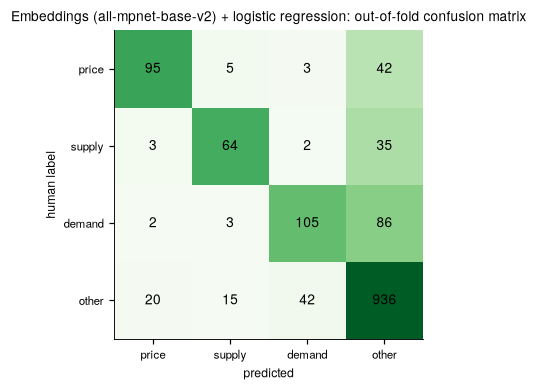

On the 160 texts drawn by simple random sampling (closest to the real mix of texts), the selected model is right for 86.9% (out of fold).
Accuracy by product (selected model, out of fold):


product
avocado     0.742
cucumber    0.863
lettuce     0.867
onion       0.847
Name: ok, dtype: float64

In [4]:
cv = pd.read_csv(TAB / "model_cv_metrics.csv", index_col="model")
names = {"keyword": "Keyword dictionary (Task 1 rules)", "zeroshot": "Zero-shot BART-large-MNLI",
         "embed_lr": "Embeddings (all-mpnet-base-v2) + logistic regression",
         "embed_lr_bge": "Embeddings (bge-base-en-v1.5) + logistic regression",
         "embed_lr_gte": "Embeddings (gte-modernbert-base) + logistic regression",
         "finetune": "Fine-tuned DistilRoBERTa"}
names |= {f"{k}_silver": f"{v} + silver" for k, v in list(names.items()) if k.startswith("embed")}
show = cv.rename(index=names)[["accuracy", "macro_f1", "macro_f1_ci_low", "macro_f1_ci_high", "cohen_kappa",
                              "f1_price", "f1_supply", "f1_demand", "f1_other"]].round(3)
display(show)
calib = [c for c in cv.columns if c.startswith("expected_")]
print("Calibration: summed out-of-fold probabilities vs. true counts (embedding models)")
display(cv.loc[cv[calib].notna().all(axis=1), calib].rename(index=names))
selected = json.load(open(TAB / "selected_model.json"))["selected_model"]
print("Selected model:", names[selected])

oof = pd.read_csv(TAB / "model_cv_predictions.csv")
cm = pd.crosstab(oof["label"], oof[selected], rownames=["human label"], colnames=["predicted"]).reindex(
    index=LABELS, columns=LABELS, fill_value=0)
fig, ax = plt.subplots(figsize=(4.2, 3.6))
ax.imshow(cm.values / cm.values.sum(1, keepdims=True), cmap="Greens", vmin=0, vmax=1)
for i in range(4):
    for j in range(4):
        ax.text(j, i, cm.values[i, j], ha="center", va="center", fontsize=9)
ax.set_xticks(range(4), LABELS); ax.set_yticks(range(4), LABELS)
ax.set_xlabel("predicted"); ax.set_ylabel("human label")
ax.set_title(f"{names[selected]}: out-of-fold confusion matrix", fontsize=9)
fig.tight_layout(); fig.savefig(FIG / "confusion_matrix.png", dpi=200); plt.show()
rnd = oof.merge(lab[["obs_id", "batch"]], on="obs_id")
rnd = rnd[rnd["batch"] == "random"]
print(f"On the {len(rnd)} texts drawn by simple random sampling (closest to the real mix of texts), the selected "
      f"model is right for {(rnd['label'] == rnd[selected]).mean():.1%} (out of fold).")
print("Accuracy by product (selected model, out of fold):")
display(oof.merge(lab[["obs_id", "product"]], on="obs_id").assign(ok=lambda d: d["label"] == d[selected])
        .groupby("product")["ok"].mean().round(3))

## 3. Classify every observation

The selected model, retrained on the whole labelled sample, gives every observation of the event dataset a
probability for each label; `pred_label` is the most likely one. Rows of the labelled sample keep their human label.

**Counting signals.** A weekly count of hard labels would be biased: a classifier that misses 40% of demand texts
undercounts demand every week, and one tuned for recall overcounts it. Our logistic regression is fitted without
class weights, so its probabilities are calibrated: in cross-validation the summed probabilities match the true
class counts (section 2, `expected_*_vs_true`). Weekly counts are therefore **expected counts**, the sum of the
class probabilities over that week's texts (probabilistic classify-and-count).

**Checking the label shares against random samples.** Calibration in cross-validation holds for texts like the
labelled ones, but most labelled texts were enriched with market keywords. We therefore compare, per product, the
mean predicted probability over the whole dataset with the share in the simple random samples (batches `random` and
`random6`, about 190 texts per product, labels from the AI annotators and the reviewer). We also tried an EM
re-estimation of the label shares (Saerens et al., 2002; `analysis.classify.prior_adjust`); it moved the estimates
slightly further from the random samples (mean absolute difference 1.9 vs 1.7 percentage points), because the
training labels already contain about 770 randomly drawn texts. The unadjusted probabilities are used.

Sentiment is `P(positive) − P(negative)` from `cardiffnlp/twitter-roberta-base-sentiment-latest`.

In [5]:
ev = read_periods("event_dataset.csv", parse_dates=["week_start", "date"]).drop_duplicates("obs_id")
cls = read_periods("classified_observations.csv.gz").drop(columns="period").drop_duplicates("obs_id")
obs = ev.merge(cls[["obs_id", "pred_label", "human_label", "sentiment"] + [f"p_{l}" for l in LABELS]],
               on="obs_id", how="left")
has_human = obs["human_label"].isin(LABELS)          # labelled sample: the human label replaces the prediction
obs.loc[has_human, "pred_label"] = obs.loc[has_human, "human_label"]
for l in LABELS:
    obs.loc[has_human, f"p_{l}"] = (obs.loc[has_human, "human_label"] == l).astype(float)
print(f"{has_human.sum()} observations carry their human label")
print(f"{len(obs):,} observations, {obs['record_id'].nunique():,} Reddit records, {obs['thread_id'].nunique():,} threads")
prev = pd.read_csv(TAB / "label_prevalence.csv")
display(prev.pivot(index="product", columns="label", values=["mean_probability_before_adjustment",
                   "estimated_share_after_adjustment", "random_sample_share"]).round(3))
dist = pd.crosstab(obs["product"], obs["pred_label"]).reindex(columns=LABELS)
expected = obs.groupby("product")[[f"p_{l}" for l in LABELS]].sum().round(0).astype(int)
expected.columns = LABELS
dist_share = expected.div(expected.sum(1), axis=0).round(3)
display(pd.concat({"most likely label": dist, "expected count": expected, "expected share": dist_share}, axis=1))
dist.to_csv(TAB / "predicted_label_counts.csv")

1456 observations carry their human label
239,639 observations, 225,926 Reddit records, 84,923 threads


mean_probability_before_adjustment                      estimated_share_after_adjustment                      random_sample_share                     
label                                demand  other  price supply                           demand  other  price supply              demand  other  price supply
product                                                                                                                                                        
avocado                               0.194  0.639  0.086  0.081                            0.152  0.770  0.034  0.044               0.217  0.494  0.205  0.084
cucumber                              0.116  0.841  0.013  0.029                            0.061  0.924  0.004  0.011               0.119  0.864  0.000  0.017
lettuce                               0.048  0.867  0.044  0.041                            0.039  0.934  0.017  0.010               0.036  0.836  0.036  0.091
onion                                 0.101  0.843  0.026  0.030                            0.052  0.938  0.002  0.008               0.197  0.738  0.000  0.066

most likely label                       expected count                       expected share                     
pred_label             price supply demand   other          price supply demand   other          price supply demand  other
product                                                                                                                    
avocado                 2642   2442   8290   36793           4141   3389  10268   32369          0.083  0.068  0.205  0.645
cucumber                 148    284   3348   35573            444   1059   4936   32914          0.011  0.027  0.125  0.836
lettuce                  567   1560    319   26209           1111   2147   1256   24141          0.039  0.075  0.044  0.842
onion                   1156   1863   5998  112447           3104   3733  12085  102542          0.026  0.031  0.099  0.844

## 4. Weekly market signals

Per product and ISO week: number of observations (`volume`), product posts per 10,000 posts in the listed
subreddits (`posts_per_10k`, removes growth of the subreddits themselves), mean sentiment, and the number and share of
price / supply / demand observations. Grey bands are the documented events in `config/events_reference.csv`.

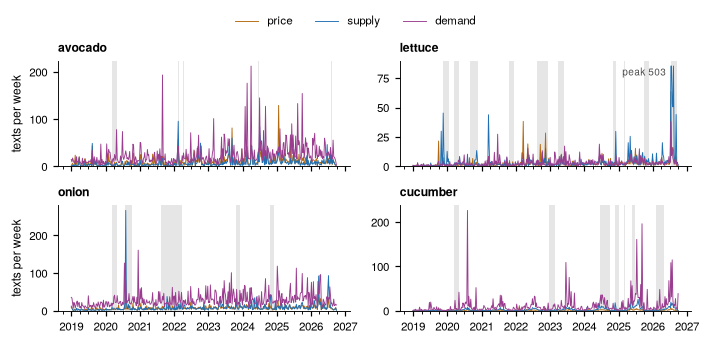

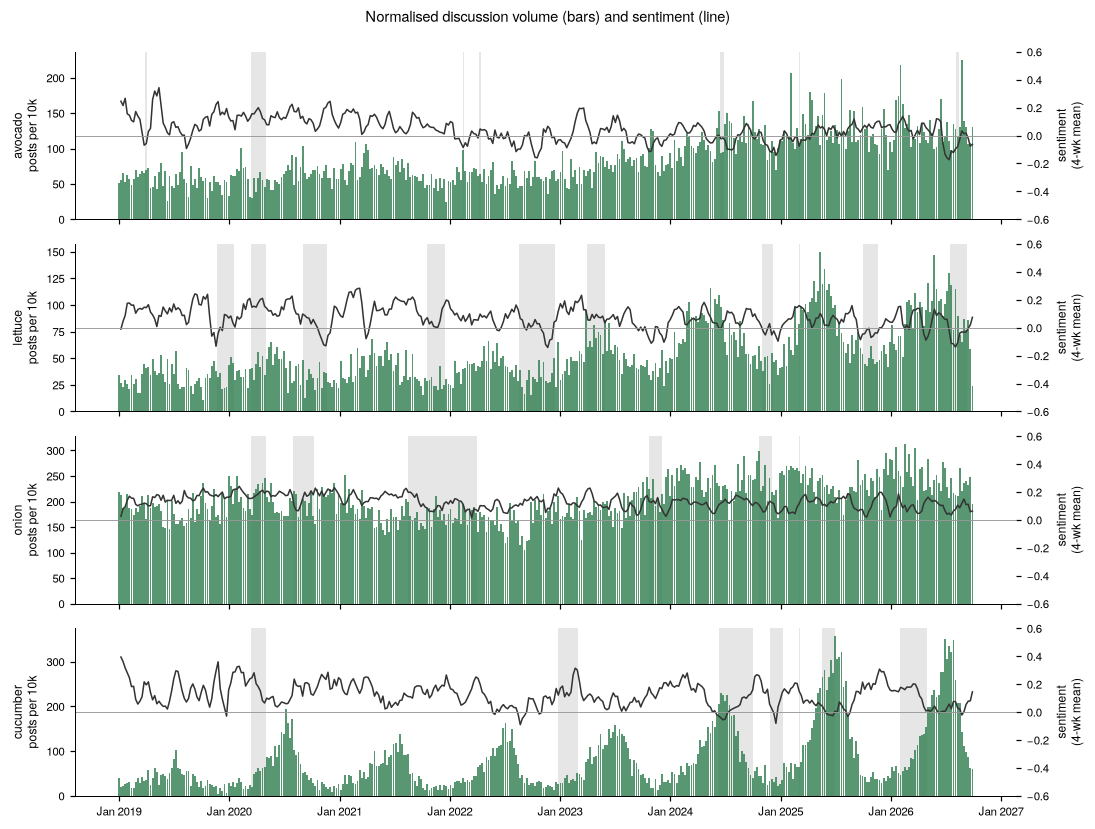

In [6]:
post_counts = read_periods("weekly_post_counts.csv", parse_dates=["week_start"])
sig = S.weekly_signals(obs, post_counts, START, END)
sig = S.add_anomalies(sig)
sig.to_csv(TAB / "weekly_signals.csv", index=False)

def shade(ax, prod, label=False):
    prev, level = None, 0
    for e in events_ref[events_ref["product"] == prod].sort_values("start_date").itertuples():
        ax.axvspan(e.start_date, e.end_date, color="0.9", zorder=0, lw=0)
        if not label:   # eight-year panels: bands only, the ids would overlap
            continue
        level = level + 1 if prev is not None and (e.start_date - prev).days < 45 else 0   # stagger close labels
        ax.text(e.start_date, 1 - 0.13 * level, f" {e.event_id}", transform=ax.get_xaxis_transform(), va="top",
                fontsize=6.5, color="0.35")
        prev = e.start_date

fig, axes = plt.subplots(2, 2, figsize=(6.5, 3.1), sharex=True)
for ax, prod in zip(axes.flat, PRODUCTS):
    g = sig[sig["product"] == prod].set_index("week_start")
    vals = g[["n_price", "n_supply", "n_demand"]]
    p997, mx = np.nanpercentile(vals.to_numpy(), 99.7), np.nanmax(vals.to_numpy())
    cap = 1.5 * p997 if mx > 3 * p997 else mx   # one outbreak week would flatten the rest of the panel
    for lab_ in ["price", "supply", "demand"]:
        ax.plot(g.index, g[f"n_{lab_}"].clip(upper=cap), color=COLORS[lab_], lw=0.6, label=lab_)
    if mx > cap:
        w = vals.max(axis=1).idxmax()
        ax.annotate(f"peak {mx:.0f}", (w, cap), xytext=(-3, -1), textcoords="offset points", fontsize=6.5,
                    ha="right", va="top", color="0.3")
    ax.set_ylim(0, cap * 1.05)
    ax.set_title(prod, loc="left", fontweight="bold")
    shade(ax, prod)
for ax in axes[:, 0]:
    ax.set_ylabel("texts per week")
for ax in axes[-1]:
    ax.xaxis.set_major_locator(mdates.YearLocator())
    ax.xaxis.set_minor_locator(mdates.MonthLocator(bymonth=[4, 7, 10]))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
fig.legend(*axes[0, 0].get_legend_handles_labels(), ncol=3, frameon=False, loc="upper center",
           bbox_to_anchor=(0.5, 1.0))
fig.tight_layout(rect=(0, 0, 1, 0.93)); fig.savefig(FIG / "weekly_signals.png", dpi=300); plt.show()

fig, axes = plt.subplots(4, 1, figsize=(10, 7.5), sharex=True)
for ax, prod in zip(axes, PRODUCTS):
    g = sig[sig["product"] == prod].set_index("week_start")
    ax.bar(g.index, g["posts_per_10k"], width=6, color="#2f7d4f", alpha=0.8)
    ax2 = ax.twinx(); ax2.plot(g.index, g["sentiment"].rolling(4, min_periods=2).mean(), color="#333", lw=1)
    ax2.axhline(0, color="0.6", lw=0.6); ax2.set_ylim(-0.6, 0.6)
    ax.set_ylabel(f"{prod}\nposts per 10k"); ax2.set_ylabel("sentiment\n(4-wk mean)")
    shade(ax, prod)
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
fig.suptitle("Normalised discussion volume (bars) and sentiment (line)", y=0.995)
fig.tight_layout(); fig.savefig(FIG / "volume_sentiment.png", dpi=200); plt.show()

## 5. Unusual weeks and the events behind them

A week is unusual for a series when it lies at least 2 standard deviations above (*increase*) or below
(*decrease*) the mean of the previous 8 weeks; otherwise *no change*. Series: log volume, mean sentiment and the
log counts of price, supply and demand observations. For each unusual week we list the words most over-represented
in that week relative to the product's whole corpus (log-odds with an informative Dirichlet prior) and the most
up-voted texts, and we match the week to a documented event within ±2 weeks.

In [7]:
import re
from collections import Counter

STOP = set(("the a an and or but if of to in on for with at by from is are was were be been it its this that these "
            "those i you he she we they my your our their me him her them as so not no do does did have has had just "
            "like get got can will would could should about what when where who how all any more most some than then "
            "there here out up down over very too also really one two im dont thats ive youre theyre its it's i'm "
            "don't i've you're they're amp https http com www reddit").split())

def tokens(text):
    return [w for w in re.findall(r"[a-z][a-z']+", str(text).lower()) if w not in STOP and len(w) > 2]

def distinctive_words(week_texts, all_counts, k=8):
    wc = Counter(w for t in week_texts for w in tokens(t))
    n_w, n_a = sum(wc.values()), sum(all_counts.values())
    if n_w == 0:
        return ""
    a0, scores = 0.01 * n_a, {}
    for w, c in wc.items():
        if c < 3:
            continue
        a = all_counts.get(w, 0) * 0.01 + 0.01
        lw = np.log((c + a) / (n_w + a0 - c - a))
        la = np.log((all_counts.get(w, 0) + a) / (n_a + a0 - all_counts.get(w, 0) - a))
        scores[w] = (lw - la) / np.sqrt(1 / (c + a) + 1 / (all_counts.get(w, 0) + a))
    return ", ".join(sorted(scores, key=scores.get, reverse=True)[:k])

zcols = {"volume": "z_volume", "price": "z_n_price", "supply": "z_n_supply", "demand": "z_n_demand",
         "sentiment": "z_sentiment"}
rows = []
for prod in PRODUCTS:
    g = sig[sig["product"] == prod]
    corpus = Counter(w for t in obs.loc[obs["product"] == prod, "text"] for w in tokens(t))
    for r in g.itertuples():
        hits = {k: getattr(r, c) for k, c in zcols.items() if pd.notna(getattr(r, c)) and abs(getattr(r, c)) >= 2}
        if not hits or r.volume < 5:
            continue
        wk = obs[(obs["product"] == prod) & (obs["week_start"] == r.week_start)]
        top = wk.sort_values("score", ascending=False).head(2)
        ev_match = events_ref[(events_ref["product"] == prod)
                              & (events_ref["start_date"] - pd.Timedelta(weeks=2) <= r.week_start)
                              & (events_ref["end_date"] + pd.Timedelta(weeks=2) >= r.week_start)]
        rows.append({"product": prod, "week_start": r.week_start.date(), "volume": r.volume,
                     "unusual_series": ", ".join(f"{k} {'increase' if v > 0 else 'decrease'} (z={v:.1f})" for k, v in hits.items()),
                     "max_abs_z": max(abs(v) for v in hits.values()),
                     "distinctive_words": distinctive_words(wk["text"], corpus),
                     "documented_event": "; ".join(ev_match["event_id"] + " " + ev_match["event_name"]),
                     "top_text": " | ".join(top["text"].astype(str).map(lambda t: re.sub(r"\s+", " ", t)).str.slice(0, 140)),
                     "top_url": " ".join(top["url"])})
unusual = pd.DataFrame(rows).sort_values(["product", "week_start"])
unusual.to_csv(TAB / "unusual_weeks.csv", index=False)
print(f"{len(unusual)} unusual product-weeks; {(unusual['documented_event'] != '').sum()} fall within 2 weeks of a documented event")
display(unusual.sort_values("max_abs_z", ascending=False).head(25)[
    ["product", "week_start", "volume", "unusual_series", "distinctive_words", "documented_event"]])

523 unusual product-weeks; 107 fall within 2 weeks of a documented event


,product,week_start,volume,unusual_series,distinctive_words,documented_event
252,lettuce,2026-07-13,1419,"volume increase (z=13.3), price increase (z=11.0), supply increase (z=20.5), demand increase (z=5.4), sent...","taylor, farms, taco, bell, lettuce, outbreak, supplier, source",E32 Cyclospora outbreak linked to Taylor Farms de Mexico iceberg lettuce
131,lettuce,2019-10-28,68,"supply increase (z=11.1), sentiment decrease (z=-3.2)","outbreak, fda, public, identified, investigation, statement, ongoing, sick",
155,lettuce,2021-03-15,241,"volume increase (z=6.2), price increase (z=8.6), supply increase (z=9.4), demand increase (z=2.2), sentime...","coli, contaminated, bacteria, goodridge, victim, poop, mitigate, toxin",
474,cucumber,2024-06-03,205,supply increase (z=8.9),"membership, burpee, recycled, males, cdn, snapped, recalled, dbs",E19 Salmonella outbreak linked to cucumbers
388,cucumber,2019-09-30,74,"volume increase (z=2.1), price increase (z=8.7), sentiment increase (z=2.1)","filling, croutons, boiled, farms, add, nuts, cheap, salad",
130,lettuce,2019-09-30,102,"volume increase (z=3.5), price increase (z=8.3), demand increase (z=2.5)","cheaper, filling, mix, cheap, buy, salad, add, croutons",
277,onion,2020-07-20,640,"volume increase (z=5.8), price increase (z=5.8), supply increase (z=3.4), demand increase (z=8.0)","grater, rings, caramelized, frikadellen, currywurst, donate, grate, pancake",E7 Salmonella Newport outbreak linked to red onions (Thomson International)
485,cucumber,2024-11-25,72,"supply increase (z=7.7), sentiment decrease (z=-4.7)","salmonella, outbreaks, wegmans, sunfed, washing, recalled, coli, incidents",E24 SunFed cucumber recall (Salmonella Typhimurium)
110,avocado,2026-03-09,72,"volume decrease (z=-3.0), price decrease (z=-7.5), supply decrease (z=-3.5)","choquette, mexicali, dorm, cafe, watermelon, survived, drying, film",
246,lettuce,2026-04-13,174,"volume increase (z=3.3), supply increase (z=7.3), sentiment decrease (z=-3.0)","bugs, washing, doors, elote, sir, chipotle, avo, properly",


**Which spikes point to real events?** Many weeks are unusual in some series (five series, two directions), so a
single unusual week means little. About 12% of product-weeks lie within two weeks of a documented event; if a kind
of spike carried no information, about 12% of its weeks would too. For each series and threshold we count the
weeks at or above it (|z| for sentiment), how many lie near a documented event, and test that share against the
base rate (one-sided binomial test).

In [8]:
from scipy.stats import binomtest
sw = sig[sig["week_start"].between(*WHOLE_WEEKS)].copy()   # whole weeks only
def near_event(prod, w):
    m = events_ref[(events_ref["product"] == prod) & (events_ref["start_date"] - pd.Timedelta(weeks=2) <= w)
                   & (events_ref["end_date"] + pd.Timedelta(weeks=2) >= w)]
    return ", ".join(m["event_id"])
sw["near_event"] = [near_event(p, w) for p, w in zip(sw["product"], sw["week_start"])]
base = (sw["near_event"] != "").mean()
rows = []
for name, col in zcols.items():
    for thr in (2, 3, 4):
        x = sw[col].abs() if name == "sentiment" else sw[col]
        hit = sw[x >= thr]
        k = int((hit["near_event"] != "").sum())
        found = sorted({e for v in hit["near_event"] if v for e in v.split(", ")})
        rows.append({"series": name, "z_at_least": thr, "weeks": len(hit), "near_documented_event": k,
                     "share": round(k / len(hit), 2) if len(hit) else np.nan,
                     "p_vs_base_rate": round(binomtest(k, len(hit), base, alternative="greater").pvalue, 4)
                     if len(hit) else np.nan,
                     "events_found": ", ".join(found)})
spikes = pd.DataFrame(rows)
spikes.to_csv(TAB / "spike_event_enrichment.csv", index=False)
print(f"{len(sw)} product-weeks; {base:.1%} lie within 2 weeks of a documented event (the base rate)")
display(spikes)

1612 product-weeks; 20.8% lie within 2 weeks of a documented event (the base rate)


,series,z_at_least,weeks,near_documented_event,share,p_vs_base_rate,events_found
0,volume,2,123,31,0.25,0.1408,"E1, E10, E11, E12, E14, E15, E16, E17, E18, E2, E20, E22, E23, E27, E29, E3, E31, E32, E4, E5, E6, E7, E9"
1,volume,3,54,13,0.24,0.3287,"E11, E14, E15, E17, E20, E23, E29, E3, E31, E32, E5, E6, E7, E9"
2,volume,4,21,6,0.29,0.2624,"E11, E14, E15, E20, E32, E5, E7, E9"
3,price,2,117,27,0.23,0.3094,"E10, E11, E12, E14, E15, E16, E17, E18, E20, E23, E29, E31, E32, E5, E6, E7, E8, E9"
4,price,3,47,14,0.30,0.0952,"E14, E15, E17, E18, E20, E29, E31, E32, E5, E6, E7, E8"
5,price,4,26,8,0.31,0.1569,"E14, E15, E17, E29, E32, E7, E8"
6,supply,2,134,42,0.31,0.0029,"E1, E11, E12, E13, E14, E15, E16, E17, E18, E19, E2, E20, E22, E23, E24, E26, E29, E3, E31, E32, E4, E5, E..."
7,supply,3,55,23,0.42,0.0003,"E1, E11, E12, E14, E15, E17, E18, E19, E20, E22, E23, E24, E26, E29, E32, E5, E6, E7, E8, E9"
8,supply,4,27,14,0.52,0.0004,"E1, E11, E12, E14, E15, E18, E19, E23, E24, E29, E32, E5, E6, E7, E9"
9,demand,2,127,26,0.20,0.5760,"E10, E11, E12, E14, E15, E16, E17, E19, E2, E20, E23, E29, E3, E31, E32, E33, E4, E5, E6, E7, E9"


## 6. USDA AMS terminal market prices

`analysis/prices.py` turns the reported price lines of all three periods into one fixed-composition weekly price
index per product (two-way fixed effects: item series × week; an item series is one market × commodity × variety ×
package × size × origin × organic combination). Index mean over 2019–2026 ≈ 100.

          price_lines  item_series  markets
product                                    
avocado        197220          820       10
cucumber       218359         1692       10
lettuce        161786          656       10
onion          488571         2546       10


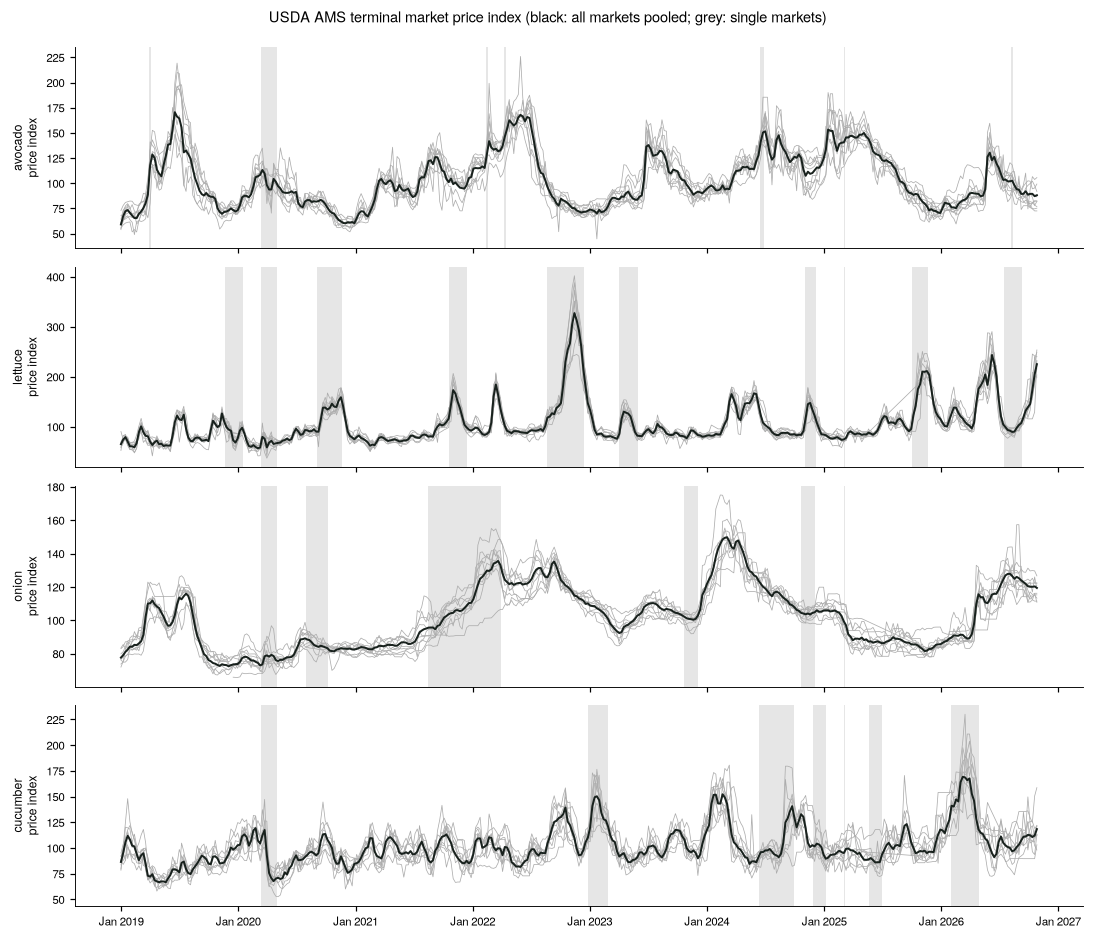

In [9]:
prices = pd.concat([P.load_prices(d / "ams_terminal_prices.csv.gz") for d in PERIODS], ignore_index=True).drop_duplicates()
widx = S.price_anomalies(P.weekly_indices(prices))
widx.to_csv(TAB / "price_index_weekly.csv", index=False)
nat = widx[widx["market"] == "ALL"]
print(prices.groupby("product").agg(price_lines=("price", "size"), item_series=("series", "nunique"),
                                    markets=("market", "nunique")))

fig, axes = plt.subplots(4, 1, figsize=(10, 8.5), sharex=True)
for ax, prod in zip(axes, PRODUCTS):
    g = nat[nat["product"] == prod]
    ax.plot(g["week_start"], g["index"], color="#18211d", lw=1.3, zorder=3)
    for mkt, gm in widx[(widx["product"] == prod) & (widx["market"] != "ALL")].groupby("market"):
        ax.plot(gm["week_start"], gm["index"], color="0.68", lw=0.5, zorder=1)
    ax.set_ylabel(f"{prod}\nprice index")
    shade(ax, prod)
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
fig.suptitle("USDA AMS terminal market price index (black: all markets pooled; grey: single markets)", y=0.995)
fig.tight_layout(); fig.savefig(FIG / "price_indices.png", dpi=200); plt.show()

**Shipments.** To tell supply from demand we also need the *quantity* reaching the market. AMS movement reports
give the pounds of each commodity shipped from US production districts and imported through ports of entry
(`data_collection/collect_ams_movement.py`). We sum them per product and week.

import    domestic (billion lb, 2019-2026)  import (billion lb, 2019-2026)
product                                                                   
avocado                               2.57                           20.14
cucumber                              1.81                           18.56
lettuce                              31.17                            2.49
onion                                33.19                            6.83


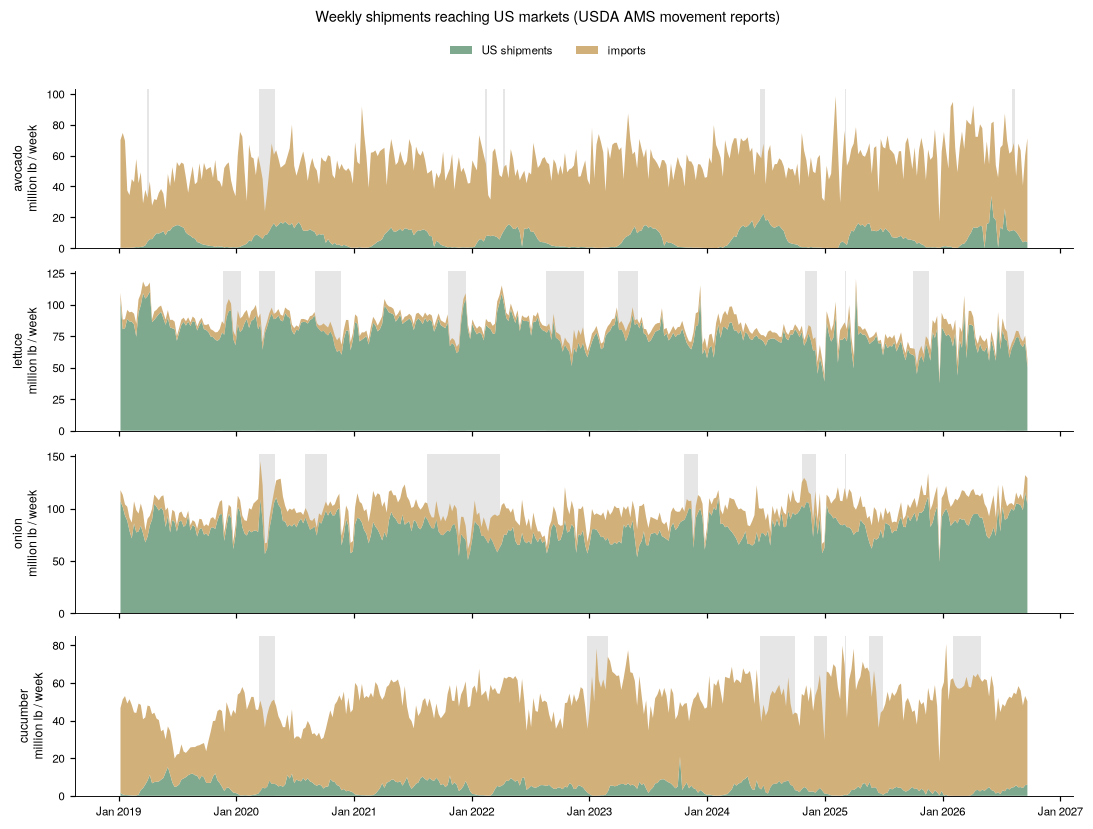

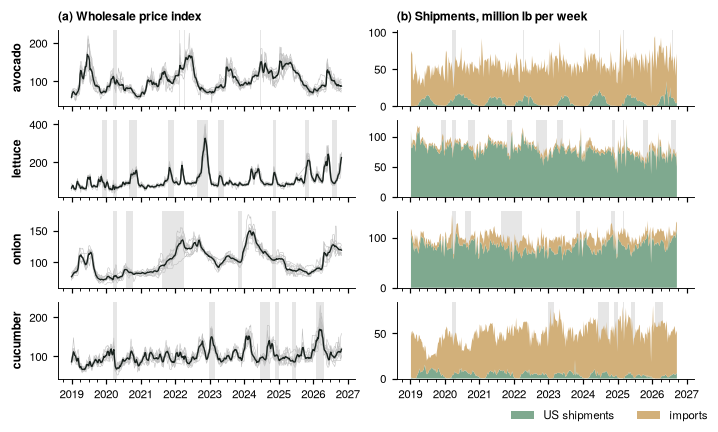

In [10]:
# weekly sums from the daily lines, so that weeks spanning two collection periods are complete
mv = read_periods("ams_movement_daily.csv.gz", parse_dates=["ship_date"]).drop(columns="period").drop_duplicates()
mv["week_start"] = mv["ship_date"] - pd.to_timedelta(mv["ship_date"].dt.weekday, unit="D")
ship = (mv.pivot_table(index=["product", "week_start"], columns="import", values="pounds", aggfunc="sum", fill_value=0)
          .rename(columns={False: "domestic_lb", True: "import_lb"}).reset_index())
ship["total_lb"] = ship["domestic_lb"] + ship["import_lb"]
ship = ship[ship["week_start"].between(*WHOLE_WEEKS)]   # whole weeks only
ship["log_lb"] = np.log(ship["total_lb"].where(ship["total_lb"] > 0))
ship_log = {p: g.set_index("week_start")["log_lb"] for p, g in ship.groupby("product")}
print(ship.groupby("product")[["domestic_lb", "import_lb"]].sum().div(1e9).round(2).rename(
    columns=lambda c: c.replace("_lb", " (billion lb, 2019-2026)")))

fig, axes = plt.subplots(4, 1, figsize=(10, 7.5), sharex=True)
for ax, prod in zip(axes, PRODUCTS):
    g = ship[ship["product"] == prod]
    ax.stackplot(g["week_start"], g["domestic_lb"] / 1e6, g["import_lb"] / 1e6, colors=["#7fa98f", "#d2b07a"],
                 labels=["US shipments", "imports"], lw=0)
    ax.set_ylabel(f"{prod}\nmillion lb / week")
    shade(ax, prod)
fig.legend(*axes[0].get_legend_handles_labels(), ncol=2, frameon=False, loc="upper center", bbox_to_anchor=(0.5, 0.965))
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
fig.suptitle("Weekly shipments reaching US markets (USDA AMS movement reports)", y=0.995)
fig.tight_layout(rect=(0, 0, 1, 0.95)); fig.savefig(FIG / "shipments.png", dpi=200); plt.show()

# Report figure: price index (left) and shipments (right) side by side, one row per product
fig, axes = plt.subplots(4, 2, figsize=(6.5, 3.9), sharex=True)
for (axp, axs), prod in zip(axes, PRODUCTS):
    g = nat[nat["product"] == prod]
    for mkt, gm in widx[(widx["product"] == prod) & (widx["market"] != "ALL")].groupby("market"):
        axp.plot(gm["week_start"], gm["index"], color="0.75", lw=0.35, zorder=1)
    axp.plot(g["week_start"], g["index"], color="#18211d", lw=0.9, zorder=3)
    gs = ship[ship["product"] == prod]
    axs.stackplot(gs["week_start"], gs["domestic_lb"] / 1e6, gs["import_lb"] / 1e6, colors=["#7fa98f", "#d2b07a"],
                  labels=["US shipments", "imports"], lw=0)
    axp.set_ylabel(prod, fontweight="bold")
    shade(axp, prod); shade(axs, prod)
axes[0, 0].set_title("(a) Wholesale price index", loc="left", fontweight="bold")
axes[0, 1].set_title("(b) Shipments, million lb per week", loc="left", fontweight="bold")
fig.legend(*axes[0, 1].get_legend_handles_labels(), loc="lower right", ncol=2, frameon=False)
for ax in axes[-1]:
    ax.xaxis.set_major_locator(mdates.YearLocator())
    ax.xaxis.set_minor_locator(mdates.MonthLocator(bymonth=[4, 7, 10]))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
fig.tight_layout(h_pad=0.6, rect=(0, 0.03, 1, 1)); fig.savefig(FIG / "prices_and_shipments.png", dpi=300); plt.show()

## 7. Timing: does the online signal lead or lag the price?

**Series-level.** For each product we correlate a weekly signal (its deviation from the previous 8 weeks, z-score)
with the price index deviation (also an 8-week trailing z-score) shifted by *k* weeks:
corr(signal<sub>t</sub>, price<sub>t+k</sub>). *k > 0* means the online signal **leads** the price, *k < 0* that
it **lags**. The grey band in the figure is ±1.96/√n, the 5% band for one pre-chosen lag between independent series.
Our series are autocorrelated and we pick the best of 17 lags, so that band is too generous. The test we use is a
rotation test (`analysis.signals.best_lag_pvalue`): the signal is shifted in time against the price by every offset of
at least 13 weeks, which keeps each series' autocorrelation and seasonality but breaks any real timing link, and the
p-value is the share of shifts whose best |r| over all lags is at least as large as the observed one. It is
approximate: in simulations with unrelated series of the same autocorrelation as ours (lag-1 about 0.2 for the
signals, 0.8 for the price), it gives p < 0.05 for about 8% of pairs instead of 5%; the simple band flags about 58%.

**Event-level.** For each documented event we find, within a window from 4 weeks before its start to 8 weeks
after its end, the first week the signal crosses z ≥ 2 and the first week the price index crosses |z| ≥ 2, and
report the difference in days (positive = signal first).

,product,signal,r_same_week,best_lag_weeks,r_at_best_lag,outside_simple_band,p_rotation,reading
0,avocado,volume,0.181,0,0.181,True,0.043,same week
1,avocado,price posts,0.115,0,0.115,True,0.217,same week
2,avocado,supply posts,0.160,0,0.160,True,0.051,same week
3,avocado,demand posts,0.182,0,0.182,True,0.000,same week
4,avocado,sentiment,0.067,0,0.067,False,0.818,same week
5,lettuce,volume,-0.025,7,0.134,True,0.219,signal leads price
6,lettuce,price posts,0.040,-5,-0.110,True,0.353,signal lags price
7,lettuce,supply posts,0.041,2,0.066,False,0.968,signal leads price
8,lettuce,demand posts,-0.068,7,0.146,True,0.000,signal leads price
9,lettuce,sentiment,-0.141,1,-0.142,True,0.243,signal leads price


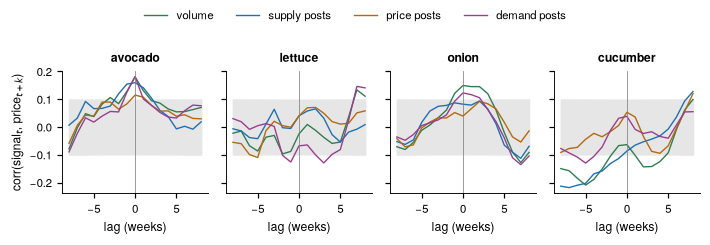

In [11]:
signal_cols = {"volume": "z_volume", "price posts": "z_n_price", "supply posts": "z_n_supply",
               "demand posts": "z_n_demand", "sentiment": "z_sentiment"}
xc_rows, xc_curves = [], {}
for prod in PRODUCTS:
    g = sig[sig["product"] == prod].set_index("week_start")
    pz = nat[nat["product"] == prod].set_index("week_start")["z_price"].reindex(g.index)
    for name, col in signal_cols.items():
        xc = S.cross_correlation(g[col], pz, max_lag=8)
        xc_curves[(prod, name)] = xc
        if xc["r"].isna().all():
            continue
        best = xc.loc[xc["r"].abs().idxmax()]
        r0 = xc.loc[xc["lag_weeks"] == 0, "r"].item()
        pval = S.best_lag_pvalue(g[col], pz, max_lag=8)
        xc_rows.append({"product": prod, "signal": name, "r_same_week": round(r0, 3),
                        "best_lag_weeks": int(best["lag_weeks"]), "r_at_best_lag": round(best["r"], 3),
                        "outside_simple_band": abs(best["r"]) > best["ci95"], "p_rotation": round(pval, 3),
                        "reading": "signal leads price" if best["lag_weeks"] > 0 else
                                   "signal lags price" if best["lag_weeks"] < 0 else "same week"})
xcorr = pd.DataFrame(xc_rows)
xcorr.to_csv(TAB / "lead_lag_crosscorrelation.csv", index=False)
display(xcorr)

fig, axes = plt.subplots(1, 4, figsize=(6.5, 2.2), sharey=True)
for ax, prod in zip(axes, PRODUCTS):
    for name, colr in [("volume", "#2f7d4f"), ("supply posts", COLORS["supply"]), ("price posts", COLORS["price"]),
                       ("demand posts", COLORS["demand"])]:
        xc = xc_curves[(prod, name)]
        ax.plot(xc["lag_weeks"], xc["r"], color=colr, lw=0.9, label=name)
    ax.fill_between(xc["lag_weeks"], -xc["ci95"], xc["ci95"], color="0.9", zorder=0)
    ax.axvline(0, color="0.5", lw=0.5); ax.set_title(prod, fontweight="bold"); ax.set_xlabel("lag (weeks)")
axes[0].set_ylabel("corr(signal$_t$, price$_{t+k}$)")
fig.legend(*axes[0].get_legend_handles_labels(), ncol=4, frameon=False, loc="upper center")
fig.tight_layout(rect=(0, 0, 1, 0.86)); fig.savefig(FIG / "lead_lag.png", dpi=300); plt.show()

In [12]:
timing = []
for e in events_ref.itertuples():
    g = sig[sig["product"] == e.product].set_index("week_start")
    pz = nat[nat["product"] == e.product].set_index("week_start")["z_price"]
    w0, w1 = e.start_date - pd.Timedelta(weeks=4), e.end_date + pd.Timedelta(weeks=8)
    p_first = S.first_crossing(pz, w0, w1, 2.0, "abs")
    row = {"event_id": e.event_id, "product": e.product, "event": e.event_name, "event_start": e.start_date.date(),
           "first_price_move_week": p_first.date() if pd.notna(p_first) else None,
           "price_direction": ("up" if pz.get(p_first, 0) > 0 else "down") if pd.notna(p_first) else None}
    for name, col in [("volume", "z_volume"), ("supply", "z_n_supply"), ("price", "z_n_price"), ("demand", "z_n_demand")]:
        s_first = S.first_crossing(g[col], w0, w1, 2.0, "up")
        row[f"first_{name}_signal_week"] = s_first.date() if pd.notna(s_first) else None
        row[f"{name}_lead_days"] = (p_first - s_first).days if pd.notna(p_first) and pd.notna(s_first) else None
    timing.append(row)
timing = pd.DataFrame(timing)
timing.to_csv(TAB / "event_timing.csv", index=False)
display(timing)

,event_id,product,event,event_start,first_price_move_week,price_direction,first_volume_signal_week,volume_lead_days,first_supply_signal_week,supply_lead_days,first_price_signal_week,price_lead_days,first_demand_signal_week,demand_lead_days
0,E1,avocado,US-Mexico border closure threat,2019-03-29,2019-03-18,up,2019-03-25,-7.0,2019-03-25,-7.0,2019-05-27,-70.0,None,NaN
1,E2,lettuce,E. coli O157:H7 outbreak linked to Salinas romaine,2019-11-20,2019-12-16,down,2019-11-18,28.0,2019-10-28,49.0,None,NaN,2020-01-27,-42.0
2,E3,avocado,COVID-19 restaurant closures and panic buying,2020-03-13,2020-02-24,up,2020-04-27,-63.0,2020-04-27,-63.0,None,NaN,2020-04-27,-63.0
3,E4,cucumber,COVID-19 restaurant closures and panic buying,2020-03-13,2020-02-17,up,2020-03-23,-35.0,2020-03-30,-42.0,2020-02-17,0.0,2020-03-23,-35.0
4,E5,lettuce,COVID-19 restaurant closures and panic buying,2020-03-13,2020-06-01,up,2020-05-11,21.0,2020-03-23,70.0,2020-05-11,21.0,2020-04-06,56.0
5,E6,onion,COVID-19 restaurant closures and panic buying,2020-03-13,None,NaN,2020-03-30,NaN,2020-03-09,NaN,2020-03-16,NaN,2020-03-30,NaN
6,E7,onion,Salmonella Newport outbreak linked to red onions (Thomson International),2020-07-31,2020-07-06,up,2020-07-20,-14.0,2020-07-20,-14.0,2020-07-20,-14.0,2020-07-20,-14.0
7,E8,lettuce,INSV and soil-disease lettuce shortage in Salinas,2020-09-01,2020-09-14,up,None,NaN,2020-10-19,-35.0,2020-08-24,21.0,None,NaN
8,E9,onion,Pacific Northwest heat wave cuts onion crop,2021-08-15,2021-07-19,up,2021-07-19,0.0,2021-10-18,-91.0,2021-11-15,-119.0,2021-07-19,0.0
9,E10,lettuce,Fall 2021 lettuce shortage at Salinas-Yuma transition,2021-10-18,2021-09-20,up,2021-09-27,-7.0,2021-09-27,-7.0,2021-10-25,-35.0,2021-09-27,-7.0


## 8. Price impact relative to the pre-event baseline

**Response window.** Produce takes days to weeks to move from field or border to a terminal market, and stock in
transit is sold first, so prices and recorded shipments respond with a lag. For every event we therefore measure
over a *response window*: the documented event dates plus `RESPONSE_WEEKS` = 2 weeks after the end. The same rule
is used for all events, for the placebo windows and for shipments.

Change of the pooled price index during the response window relative to its mean over the 8 weeks before the event
(mean and peak change), and the same calendar-window change in the other study years as a seasonality control
(`seasonally_adjusted_pct` = event-year change minus the average other-year change, in log points). Other-year
windows that overlap another documented event of the product are not used as comparisons.
Per-market ranges show how uniform the move was across the 10 terminal markets.

`overlaps_with` lists other documented events of the same product whose dates fall inside the 8-week baseline or the
response window. Their effects cannot be separated: in 2022 the Wendy's romaine outbreak (E14) runs into the start of
the INSV lettuce shortage (E15), and in 2024 the cucumber Salmonella outbreak (E19) runs into the viral salad trend (E21).

In [13]:
RESPONSE_WEEKS = 2
events_ref["response_end"] = events_ref["end_date"] + pd.Timedelta(weeks=RESPONSE_WEEKS)
def event_windows(prod):   # documented response windows of a product (kept out of seasonal and placebo baselines)
    return [(r.start_date, r.response_end) for r in events_ref.itertuples() if r.product == prod]

def overlapping(e, pre_weeks=8):   # other events of the product dated inside this event's baseline or response window
    lo, hi = e.start_date - pd.Timedelta(weeks=pre_weeks), e.response_end
    return ", ".join(r.event_id for r in events_ref.itertuples() if r.product == e.product
                     and r.event_id != e.event_id and r.start_date <= hi and r.end_date >= lo)

impact = []
for e in events_ref.itertuples():
    li = nat[nat["product"] == e.product].set_index("week_start")["log_index"]
    r = S.price_impact(li, e.start_date, e.response_end, exclude=event_windows(e.product))
    mk = []
    for mkt, gm in widx[(widx["product"] == e.product) & (widx["market"] != "ALL")].groupby("market"):
        mk.append(S.price_impact(gm.set_index("week_start")["log_index"], e.start_date, e.response_end,
                                 exclude=event_windows(e.product))["mean_change_pct"])
    mk = [m for m in mk if pd.notna(m)]
    impact.append({"event_id": e.event_id, "product": e.product, "event": e.event_name,
                   **{k: round(v, 1) if isinstance(v, float) else v for k, v in r.items()},
                   "market_range_pct": f"{min(mk):.0f} to {max(mk):.0f}" if mk else "",
                   "overlaps_with": overlapping(e)})
impact = pd.DataFrame(impact)
impact.to_csv(TAB / "event_price_impact.csv", index=False)
display(impact)

,event_id,product,event,mean_change_pct,peak_change_pct,same_window_other_years_pct,seasonally_adjusted_pct,n_comparison_years,market_range_pct,overlaps_with
0,E1,avocado,US-Mexico border closure threat,70.2,76.9,21.7,39.8,1,48 to 91,
1,E2,lettuce,E. coli O157:H7 outbreak linked to Salinas romaine,-16.6,-32.6,NaN,NaN,0,-25 to -11,
2,E3,avocado,COVID-19 restaurant closures and panic buying,5.1,18.4,31.9,-20.3,1,-3 to 18,
3,E4,cucumber,COVID-19 restaurant closures and panic buying,-26.2,-38.4,-12.7,-15.4,3,-40 to -9,
4,E5,lettuce,COVID-19 restaurant closures and panic buying,7.6,24.3,6.4,1.2,3,-5 to 17,
5,E6,onion,COVID-19 restaurant closures and panic buying,1.7,4.3,12.9,-10.0,2,-4 to 11,
6,E7,onion,Salmonella Newport outbreak linked to red onions (Thomson International),1.4,6.0,-11.2,14.2,2,-3 to 10,
7,E8,lettuce,INSV and soil-disease lettuce shortage in Salinas,47.2,76.1,NaN,NaN,0,36 to 57,
8,E9,onion,Pacific Northwest heat wave cuts onion crop,24.0,49.6,-12.1,41.1,1,9 to 42,E11
9,E10,lettuce,Fall 2021 lettuce shortage at Salinas-Yuma transition,28.7,79.8,-0.8,29.7,1,18 to 36,


**In dollars.** The index is relative. For a concrete reading, the most often reported conventional item of each
product (for example a carton of 24 film-wrapped iceberg heads) in the 10 markets: median price per package in the
8 weeks before the event, during the response window, and the highest weekly median. These figures are not
seasonally adjusted.

In [14]:
conv = prices[prices["organic"].astype(str).str.upper() != "Y"].copy()
conv["report_date"] = pd.to_datetime(conv["report_date"])
item_cols = ["commodity", "variety", "package", "item_size"]
dollars = []
for e in events_ref.itertuples():
    g = conv[conv["product"] == e.product]
    top = g.groupby(item_cols, dropna=False).size().idxmax()
    g = g[(g[item_cols].fillna("") == pd.Series(top, index=item_cols).fillna("")).all(axis=1)]
    pre = g[(g["report_date"] >= e.start_date - pd.Timedelta(weeks=8)) & (g["report_date"] < e.start_date)]
    dur = g[(g["report_date"] >= e.start_date) & (g["report_date"] <= e.response_end)]
    item = " ".join(str(v) for v in top if pd.notna(v) and str(v) not in ("", "NA"))
    dollars.append({"event_id": e.event_id, "item": item, "median_before_usd": pre["price"].median(),
                    "median_during_usd": dur["price"].median(),
                    "highest_weekly_median_usd": dur.groupby("week_start")["price"].median().max(),
                    "price_lines_before_during": f"{len(pre)} / {len(dur)}"})
dollars = pd.DataFrame(dollars).round(2)
dollars.to_csv(TAB / "event_price_examples_usd.csv", index=False)
display(dollars)

,event_id,item,median_before_usd,median_during_usd,highest_weekly_median_usd,price_lines_before_during
0,E1,Avocados HASS cartons 2 layer 48s,30.00,60.00,63.00,639 / 241
1,E2,"Lettuce, Iceberg cartons 24s film wrapped",25.00,25.50,37.00,810 / 918
2,E3,Avocados HASS cartons 2 layer 48s,47.12,49.62,59.00,814 / 863
3,E4,Cucumbers 1 1/9 bushel cartons medium,28.25,19.00,38.00,960 / 1259
4,E5,"Lettuce, Iceberg cartons 24s film wrapped",17.50,19.00,25.00,725 / 951
5,E6,"Onions, Dry YELLOW 50 lb sacks jumbo",15.62,14.00,15.00,1356 / 1703
6,E7,"Onions, Dry YELLOW 50 lb sacks jumbo",16.50,16.50,18.50,1382 / 2008
7,E8,"Lettuce, Iceberg cartons 24s film wrapped",21.00,33.00,45.00,897 / 1519
8,E9,"Onions, Dry YELLOW 50 lb sacks jumbo",18.50,25.00,32.00,1492 / 6545
9,E10,"Lettuce, Iceberg cartons 24s film wrapped",28.00,34.00,62.25,792 / 1030


## 9. Supply shock or demand shift?

Economics tells supply shocks from demand shifts by how price and quantity move together: a **supply shock** raises
the price while less product reaches the market; a **demand shift** moves price and quantity in the same direction.
We first read each event from the market data alone, then ask whether the online talk tells the same story.

**Market reading.** For the price index and for weekly national shipments we take the seasonally adjusted change
over the response window (section 8: mean during the window vs. the 8 weeks before, minus the same calendar change
in the other years). To judge whether a change is large we compare it with the same statistic for every other window
of the same length in 2019–2026 that does not overlap a documented event of the product (a placebo distribution),
and report its percentile.

* Price: percentile ≥ 90 = unusual rise, ≤ 10 = unusual fall.
* Shipments: percentile ≤ 25 = fell, ≥ 75 = rose, otherwise flat.

| Price | Shipments | Market reading |
|---|---|---|
| unusual rise | fell | **supply shock** |
| unusual rise | flat or rose | **demand increase** |
| unusual fall | fell or flat | **demand decrease** |
| unusual fall | rose | **supply increase** |
| no unusual move | any | no clear price effect |

**Online reading.** Expected counts of *supply* and *demand* texts (section 3) during the event dates
(online talk reacts at once, so no response lag) vs. the 8 weeks before, as a rate ratio with a 95% Poisson interval. A kind of talk "rose" when its interval is above 1 and it
rose more than background (*other*) talk about the product. Supply talk rising (at least as much as demand talk) →
*supply*; demand talk rising more → *demand*. Note that by our codebook, reports of recalls and products pulled from
shelves count as supply talk; people avoiding a product count as demand talk.

In [15]:
def counts(prod, s0, s1):
    g = obs[(obs["product"] == prod) & (obs["week_start"] >= s0) & (obs["week_start"] <= s1)]
    return {l: float(g[f"p_{l}"].sum()) for l in LABELS} | {"n": len(g), "sentiment": g["sentiment"].mean()}

def wk(d):   # Monday of the week containing d
    d = pd.Timestamp(d); return d - pd.Timedelta(days=d.weekday())

fmt = lambda t: f"{t[0]:.2f} ({t[1]:.2f}-{t[2]:.2f})"
rnd = lambda x, d=None: (round(x, d) if d else round(x)) if pd.notna(x) else np.nan   # NaN: no usable comparison year
verdict = []
for e in events_ref.itertuples():
    s0, s1 = wk(e.start_date), wk(e.end_date)
    w_dur, w_pre = (s1 - s0).days // 7 + 1, 8
    others = event_windows(e.product)
    # market reading (response window)
    li = nat[nat["product"] == e.product].set_index("week_start")["log_index"]
    sa = "seasonally_adjusted_pct"
    p_pct = S.placebo_percentile(li, e.start_date, e.response_end, exclude=others, stat=sa)["percentile"]
    q = S.price_impact(ship_log[e.product], e.start_date, e.response_end, exclude=others)
    q_pct = S.placebo_percentile(ship_log[e.product], e.start_date, e.response_end, exclude=others, stat=sa)["percentile"]
    p_up, p_down = p_pct >= 90, p_pct <= 10
    q_dir = "fell" if q_pct <= 25 else "rose" if q_pct >= 75 else "flat"
    market = ("supply shock" if p_up and q_dir == "fell" else "demand increase" if p_up else
              "supply increase" if p_down and q_dir == "rose" else "demand decrease" if p_down else
              "no clear price effect")
    if pd.isna(p_pct) or pd.isna(q_pct):
        market = "no comparison year"
    # online reading
    pre = counts(e.product, s0 - pd.Timedelta(weeks=w_pre), s0 - pd.Timedelta(days=1))
    dur = counts(e.product, s0, s1)
    rr = {l: S.rate_ratio(dur[l], w_dur, pre[l], w_pre) for l in LABELS}
    rose = {l: rr[l][1] > 1 and rr[l][0] > rr["other"][0] for l in ["supply", "demand"]}
    online = ("supply" if rose["supply"] and (not rose["demand"] or rr["supply"][0] >= rr["demand"][0]) else
              "demand" if rose["demand"] else "no rise in supply or demand talk")
    agree = ("yes" if (market.startswith("supply") and online == "supply")
                      or (market.startswith("demand") and online == "demand") else
             "no" if market != "no clear price effect" and online in ("supply", "demand") else "-")
    imp = impact.set_index("event_id").loc[e.event_id]
    verdict.append({"event_id": e.event_id, "product": e.product, "event": e.event_name,
                    "price_change_pct": imp["mean_change_pct"], "price_seasonally_adjusted_pct": imp[sa],
                    "price_percentile": rnd(p_pct), "shipments_change_pct": rnd(q["mean_change_pct"], 1),
                    "shipments_seasonally_adjusted_pct": rnd(q[sa], 1), "shipments_percentile": rnd(q_pct),
                    "shipments": q_dir,
                    "market_reading": market,
                    "supply_talk_rate_ratio": fmt(rr["supply"]), "demand_talk_rate_ratio": fmt(rr["demand"]),
                    "price_talk_rate_ratio": fmt(rr["price"]), "other_talk_rate_ratio": fmt(rr["other"]),
                    "supply_talk_before_during": f"{pre['supply']:.0f} / {dur['supply']:.0f}",
                    "demand_talk_before_during": f"{pre['demand']:.0f} / {dur['demand']:.0f}",
                    "weeks_before_during": f"{w_pre} / {w_dur}",
                    "online_reading": online, "readings_agree": agree, "expected": e.hypothesis,
                    "overlaps_with": overlapping(e)})
verdict = pd.DataFrame(verdict)
verdict.to_csv(TAB / "event_supply_vs_demand.csv", index=False)
display(verdict)

,event_id,product,event,price_change_pct,price_seasonally_adjusted_pct,price_percentile,shipments_change_pct,shipments_seasonally_adjusted_pct,shipments_percentile,shipments,...,demand_talk_rate_ratio,price_talk_rate_ratio,other_talk_rate_ratio,supply_talk_before_during,demand_talk_before_during,weeks_before_during,online_reading,readings_agree,expected,overlaps_with
0,E1,avocado,US-Mexico border closure threat,70.2,39.8,96.0,-18.1,-11.9,10.0,fell,...,1.33 (0.87-2.03),1.76 (1.12-2.76),1.35 (1.09-1.68),21 / 26,85 / 28,8 / 2,supply,yes,supply,
1,E2,lettuce,E. coli O157:H7 outbreak linked to Salinas romaine,-16.6,NaN,NaN,11.4,NaN,NaN,flat,...,0.95 (0.46-1.96),0.45 (0.23-0.85),1.23 (1.04-1.46),36 / 87,14 / 15,8 / 9,supply,no,demand,
2,E3,avocado,COVID-19 restaurant closures and panic buying,5.1,-20.3,14.0,-9.4,-5.8,23.0,fell,...,0.85 (0.70-1.03),0.46 (0.31-0.68),1.11 (0.98-1.26),49 / 29,213 / 181,8 / 8,no rise in supply or demand talk,-,demand,
3,E4,cucumber,COVID-19 restaurant closures and panic buying,-26.2,-15.4,8.0,-9.1,-8.4,17.0,fell,...,1.95 (1.21-3.15),1.13 (0.39-3.21),2.69 (2.20-3.28),1 / 6,25 / 50,8 / 8,no rise in supply or demand talk,-,demand,
4,E5,lettuce,COVID-19 restaurant closures and panic buying,7.6,1.2,51.0,-5.0,-17.6,0.0,fell,...,1.51 (0.73-3.13),1.61 (0.59-4.39),1.80 (1.52-2.13),11 / 16,11 / 18,8 / 8,no rise in supply or demand talk,-,demand,
5,E6,onion,COVID-19 restaurant closures and panic buying,1.7,-10.0,13.0,5.4,1.2,54.0,flat,...,1.44 (1.16-1.79),1.68 (1.01-2.80),1.51 (1.40-1.62),22 / 45,136 / 197,8 / 8,supply,-,demand,
6,E7,onion,Salmonella Newport outbreak linked to red onions (Thomson International),1.4,14.2,79.0,-1.7,3.3,69.0,flat,...,0.88 (0.75-1.04),1.94 (1.34-2.82),1.11 (1.04-1.18),31 / 386,267 / 324,8 / 11,supply,-,demand,
7,E8,lettuce,INSV and soil-disease lettuce shortage in Salinas,47.2,NaN,NaN,-10.1,NaN,NaN,flat,...,0.74 (0.38-1.44),1.25 (0.64-2.43),0.75 (0.64-0.87),17 / 44,16 / 18,8 / 12,no rise in supply or demand talk,-,supply,
8,E9,onion,Pacific Northwest heat wave cuts onion crop,24.0,41.1,100.0,-11.6,-20.3,0.0,fell,...,0.99 (0.85-1.15),1.13 (0.83-1.54),1.15 (1.09-1.21),49 / 295,215 / 908,8 / 34,supply,yes,supply,E11
9,E10,lettuce,Fall 2021 lettuce shortage at Salinas-Yuma transition,28.7,29.7,76.0,-7.8,-7.2,16.0,fell,...,0.34 (0.16-0.74),1.03 (0.45-2.39),0.71 (0.60-0.85),20 / 15,23 / 8,8 / 9,no rise in supply or demand talk,-,supply,


## 10. Unusual weeks without a documented event

Large online anomalies that are not near a documented event, with whether the price index also moved
(|z| ≥ 2) within ±4 weeks. These are candidate market events found by the data alone.

In [16]:
cand = unusual[(unusual["documented_event"] == "") & (unusual["volume"] >= 10)].copy()
def price_move_near(prod, wk):
    pz = nat[nat["product"] == prod].set_index("week_start")["z_price"]
    w = pd.Timestamp(wk)
    near = pz[(pz.index >= w - pd.Timedelta(weeks=4)) & (pz.index <= w + pd.Timedelta(weeks=4))]
    big = near[near.abs() >= 2]
    return f"{big.index[0].date()} ({'up' if big.iloc[0] > 0 else 'down'})" if len(big) else ""
cand["price_move_within_4wk"] = [price_move_near(p, w) for p, w in zip(cand["product"], cand["week_start"])]
cand = cand.sort_values("max_abs_z", ascending=False).head(15)
cand.to_csv(TAB / "undocumented_unusual_weeks.csv", index=False)
display(cand[["product", "week_start", "volume", "unusual_series", "distinctive_words", "price_move_within_4wk", "top_text"]])

,product,week_start,volume,unusual_series,distinctive_words,price_move_within_4wk,top_text
131,lettuce,2019-10-28,68,"supply increase (z=11.1), sentiment decrease (z=-3.2)","outbreak, fda, public, identified, investigation, statement, ongoing, sick",2019-10-07 (up),FDA hid romaine-related outbreak from public view for more than 6 weeks | If you can't get to the article:...
155,lettuce,2021-03-15,241,"volume increase (z=6.2), price increase (z=8.6), supply increase (z=9.4), demand increase (z=2.2), sentime...","coli, contaminated, bacteria, goodridge, victim, poop, mitigate, toxin",2021-02-15 (down),B.C. boy permanently brain damaged after eating lettuce contaminated with E. coli | This is one of the sad...
388,cucumber,2019-09-30,74,"volume increase (z=2.1), price increase (z=8.7), sentiment increase (z=2.1)","filling, croutons, boiled, farms, add, nuts, cheap, salad",2019-09-09 (up),"What else are you adding to the salad? The spring mix is just the base. I like to add a precut slaw mix, c..."
130,lettuce,2019-09-30,102,"volume increase (z=3.5), price increase (z=8.3), demand increase (z=2.5)","cheaper, filling, mix, cheap, buy, salad, add, croutons",2019-10-07 (up),Is there a cheap way of eating salad/greens? I've been buying spring mix boxes (mixed box of fifty differe...
110,avocado,2026-03-09,72,"volume decrease (z=-3.0), price decrease (z=-7.5), supply decrease (z=-3.5)","choquette, mexicali, dorm, cafe, watermelon, survived, drying, film",2026-03-30 (up),"Tuna and watermelon aguachile, Szechuan oil Marinated watermelon with tuna and watermelon aguachile, finis..."
246,lettuce,2026-04-13,174,"volume increase (z=3.3), supply increase (z=7.3), sentiment decrease (z=-3.0)","bugs, washing, doors, elote, sir, chipotle, avo, properly",2026-04-20 (up),"Dont eat the lettuce Its getting to be summer, so that means its bug season. Speaking from experience as a..."
7,avocado,2019-08-12,259,"volume increase (z=7.3), price increase (z=4.3), supply increase (z=6.0), demand increase (z=5.9), sentime...","drugs, cartels, cartel, war, avocados, violence, gangs, blood",,Mexican gang hung 9 dead bodies from a bridge...linked to control of the avocado trade | The cartels contr...
118,avocado,2026-09-28,28,"volume decrease (z=-7.2), price decrease (z=-3.5), supply decrease (z=-3.2), demand decrease (z=-3.5)","muchim, maize, tallow, bark, course, quit, relatively, cooks",2026-09-07 (down),"All TJ's Items Breakfast Tacos: Spicy Spuds, Organic Brown Eggs, Hatch Chile Salsa, Bird's Eye Chile Salsa..."
431,cucumber,2022-02-07,65,"price increase (z=7.0), supply increase (z=2.7)","remesh, lag, marked, panels, deviled, carbonated, fold, cider",2022-01-10 (up),$1 worth of cucumbers gets me 1 cucumber | OP forgot to mention they had to wait 50-70 days for the cucumb...
29,avocado,2021-01-04,247,"volume increase (z=6.9), price increase (z=2.5), supply increase (z=2.6), demand increase (z=3.8)","lime, quality, acid, guac, ingredients, difference, salt, different",2021-01-04 (up),"I think guac is one of those things where the proportions make a huge difference, especially when it comes..."


## 11. Cross-check with Google search interest (US)

Google Trends gives weekly US search interest for four terms per product: the product name alone and with "price",
"shortage" and "recall" (`data_collection/collect_google_trends.py`). Google scales each term to 0-100, so each week
is compared only with the previous 8 weeks of the same term, as for the Reddit series (log scale, same floor).
Searches are a second, independent public signal: if Reddit spikes mark real events, search spikes should fall near
the same events. Shortage and recall searches together correspond to Reddit's supply label (recalls are supply).

In [17]:
# Google scales each download window on its own: z-scores within each collection period
gt = read_periods("google_trends_weekly.csv", parse_dates=["week_start"])
gt = gt.sort_values("period").drop_duplicates(["product", "series", "week_start"], keep="last")
gt = gt.sort_values(["product", "series", "week_start"])
gt["z"] = gt.groupby(["product", "series", "period"])["interest"].transform(
    lambda s: S.trailing_z(np.log1p(s), 8, min_sd=0.2))
gw = gt.pivot_table(index=["product", "week_start"], columns="series", values="z").add_prefix("gz_").reset_index()
gw["gz_shortage_or_recall"] = gw[["gz_shortage", "gz_recall"]].max(axis=1)
sg = sw.merge(gw, on=["product", "week_start"], how="left")   # same whole weeks and base rate as section 5

rows = []
for name in ["total", "price", "shortage", "recall", "shortage_or_recall"]:
    for thr in (2, 3, 4):
        hit = sg[sg[f"gz_{name}"] >= thr]
        k = int((hit["near_event"] != "").sum())
        found = sorted({e for v in hit["near_event"] if v for e in v.split(", ")})
        rows.append({"search_terms": name, "z_at_least": thr, "weeks": len(hit), "near_documented_event": k,
                     "share": round(k / len(hit), 2) if len(hit) else np.nan,
                     "p_vs_base_rate": round(binomtest(k, len(hit), base, alternative="greater").pvalue, 4)
                     if len(hit) else np.nan,
                     "events_found": ", ".join(found)})
trend_spikes = pd.DataFrame(rows)
trend_spikes.to_csv(TAB / "trends_spike_event_enrichment.csv", index=False)
print(f"base rate {base:.1%} of {len(sg)} product-weeks, as in section 5")
display(trend_spikes)

base rate 20.8% of 1612 product-weeks, as in section 5


,search_terms,z_at_least,weeks,near_documented_event,share,p_vs_base_rate,events_found
0,total,2,17,9,0.53,0.0035,"E1, E12, E2, E22, E32, E4, E7"
1,total,3,5,3,0.60,0.0646,"E2, E32"
2,total,4,2,2,1.00,0.0434,"E2, E32"
3,price,2,63,17,0.27,0.1483,"E1, E12, E14, E15, E19, E2, E22, E29, E30, E32, E5, E7, E8"
4,price,3,20,7,0.35,0.1037,"E1, E12, E22, E29, E30, E32"
5,price,4,8,2,0.25,0.5212,"E22, E29"
6,shortage,2,59,25,0.42,0.0002,"E1, E10, E11, E12, E14, E15, E17, E19, E21, E30, E5, E6, E7, E8, E9"
7,shortage,3,35,12,0.34,0.0457,"E1, E10, E12, E14, E15, E19, E21, E30, E5, E6, E7, E8, E9"
8,shortage,4,34,12,0.35,0.0368,"E1, E10, E12, E14, E15, E19, E21, E30, E5, E6, E7, E8, E9"
9,recall,2,78,35,0.45,0.0000,"E1, E10, E11, E12, E13, E14, E15, E17, E18, E19, E2, E20, E21, E22, E23, E24, E29, E31, E32, E7, E8, E9"


**Do the two sources spike in the same weeks?** Every week in which Reddit supply talk or Google shortage/recall
searches reach z ≥ 3, and whether the other source does too within one week.

In [18]:
def spikes_within(prod, week, col, weeks=1, thr=3):
    m = sg[(sg["product"] == prod) & ((sg["week_start"] - week).abs() <= pd.Timedelta(weeks=weeks))]
    return bool((m[col] >= thr).any())

agree = sg[(sg["z_n_supply"] >= 3) | (sg["gz_shortage_or_recall"] >= 3)].copy()
agree["reddit_supply_spike"] = agree["z_n_supply"] >= 3
agree["google_spike"] = agree["gz_shortage_or_recall"] >= 3
agree["reddit_within_1wk"] = [spikes_within(p, w, "z_n_supply") for p, w in zip(agree["product"], agree["week_start"])]
agree["google_within_1wk"] = [spikes_within(p, w, "gz_shortage_or_recall")
                              for p, w in zip(agree["product"], agree["week_start"])]
agree["z_reddit_supply"] = agree["z_n_supply"].round(2)
agree["z_google_shortage_or_recall"] = agree["gz_shortage_or_recall"].round(2)
agree = agree[["product", "week_start", "near_event", "z_reddit_supply", "z_google_shortage_or_recall",
               "reddit_supply_spike", "google_spike", "reddit_within_1wk", "google_within_1wk"]]
agree = agree.sort_values(["product", "week_start"])
agree.to_csv(TAB / "reddit_google_spike_agreement.csv", index=False, date_format="%Y-%m-%d")
r_, g_ = agree[agree["reddit_supply_spike"]], agree[agree["google_spike"]]
print(f"{len(r_)} Reddit supply spikes, {int(r_['google_within_1wk'].sum())} with a Google spike within a week; "
      f"{len(g_)} Google shortage/recall spikes, {int(g_['reddit_within_1wk'].sum())} with a Reddit spike within a week")
display(agree[agree["reddit_supply_spike"] & agree["google_within_1wk"]])

55 Reddit supply spikes, 16 with a Google spike within a week; 84 Google shortage/recall spikes, 21 with a Reddit spike within a week


,product,week_start,near_event,z_reddit_supply,z_google_shortage_or_recall,reddit_supply_spike,google_spike,reddit_within_1wk,google_within_1wk
11,avocado,2019-03-25,E1,4.24,23.08,True,True,True,True
161,avocado,2022-02-07,E12,4.18,NaN,True,False,True,True
162,avocado,2022-02-14,E12,3.05,23.08,True,True,True,True
685,cucumber,2024-06-03,E19,8.93,11.53,True,True,True,True
710,cucumber,2024-11-25,E24,7.73,8.93,True,True,True,True
734,cucumber,2025-05-12,E29,4.12,0.00,True,False,True,True
848,lettuce,2019-10-28,,11.14,4.13,True,True,True,True
869,lettuce,2020-03-23,E5,4.42,0.00,True,False,True,True
899,lettuce,2020-10-19,E8,3.41,2.47,True,False,True,True
1198,lettuce,2026-07-13,E32,20.50,3.40,True,True,True,True


**When does each source peak around each event?** Within each event's window (±2 weeks), the week with the most
Reddit supply texts and the week with the highest search interest for each term.

In [19]:
rows = []
for e in events_ref.sort_values("start_date").itertuples():
    lo, hi = e.start_date - pd.Timedelta(weeks=2), e.end_date + pd.Timedelta(weeks=2)
    r = sig[(sig["product"] == e.product) & sig["week_start"].between(lo, hi)]
    g = gt[(gt["product"] == e.product) & gt["week_start"].between(lo, hi)]
    row = {"event_id": e.event_id, "product": e.product, "event_name": e.event_name,
           "reddit_supply_peak": r.loc[r["n_supply"].idxmax(), "week_start"].date()}
    for s_ in ["shortage", "recall", "price"]:
        gs = g[g["series"] == s_]
        row[f"google_{s_}_peak"] = gs.loc[gs["interest"].idxmax(), "week_start"].date() if gs["interest"].max() > 0 else ""
    gaps = [abs((pd.Timestamp(row[f"google_{s_}_peak"]) - pd.Timestamp(row["reddit_supply_peak"])).days) // 7
            for s_ in ["shortage", "recall"] if row[f"google_{s_}_peak"] != ""]
    row["weeks_from_reddit_peak_to_nearest_google_shortage_or_recall_peak"] = min(gaps) if gaps else np.nan
    w = sg[(sg["product"] == e.product) & sg["week_start"].between(lo, hi)]
    row["google_shortage_or_recall_spike"] = bool((w["gz_shortage_or_recall"] >= 3).any())
    row["reddit_supply_spike"] = bool((w["z_n_supply"] >= 3).any())
    rows.append(row)
peaks = pd.DataFrame(rows)
peaks.to_csv(TAB / "event_search_peaks.csv", index=False)
display(peaks)

,event_id,product,event_name,reddit_supply_peak,google_shortage_peak,google_recall_peak,google_price_peak,weeks_from_reddit_peak_to_nearest_google_shortage_or_recall_peak,google_shortage_or_recall_spike,reddit_supply_spike
0,E1,avocado,US-Mexico border closure threat,2019-03-25,2019-04-01,2019-03-25,2019-04-01,0.0,True,True
1,E2,lettuce,E. coli O157:H7 outbreak linked to Salinas romaine,2019-11-18,,2019-11-25,2019-11-25,1.0,False,False
2,E3,avocado,COVID-19 restaurant closures and panic buying,2020-04-27,,,2020-03-09,NaN,False,False
3,E4,cucumber,COVID-19 restaurant closures and panic buying,2020-05-04,,,2020-05-04,NaN,False,False
4,E5,lettuce,COVID-19 restaurant closures and panic buying,2020-05-11,2020-03-30,2020-03-02,2020-05-11,6.0,True,True
5,E6,onion,COVID-19 restaurant closures and panic buying,2020-03-09,2020-04-13,,2020-04-27,5.0,True,True
6,E7,onion,Salmonella Newport outbreak linked to red onions (Thomson International),2020-08-03,2020-08-03,2020-08-03,2020-08-03,0.0,True,True
7,E8,lettuce,INSV and soil-disease lettuce shortage in Salinas,2020-11-09,2020-10-26,2020-11-09,2020-09-07,0.0,True,True
8,E9,onion,Pacific Northwest heat wave cuts onion crop,2021-10-18,2021-08-16,2021-10-18,2022-03-14,0.0,True,True
9,E10,lettuce,Fall 2021 lettuce shortage at Salinas-Yuma transition,2021-10-25,2021-11-15,2021-12-20,2021-11-01,3.0,True,False


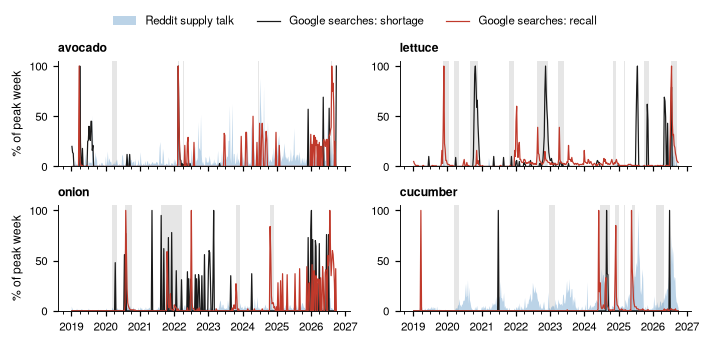

In [20]:
fig, axes = plt.subplots(2, 2, figsize=(6.5, 3.1), sharex=True)
for ax, prod in zip(axes.flat, PRODUCTS):
    r = sig[sig["product"] == prod].set_index("week_start")["n_supply"]
    ax.fill_between(r.index, 100 * r / r.max(), color=COLORS["supply"], alpha=0.3, lw=0, label="Reddit supply talk")
    for s_, col in [("shortage", "0.1"), ("recall", "#c0392b")]:
        g = gt[(gt["product"] == prod) & (gt["series"] == s_)].set_index("week_start")["interest"]
        ax.plot(g.index, g, color=col, lw=0.8, label=f"Google searches: {s_}")
    ax.set_ylim(0, 105)
    ax.set_title(prod, loc="left", fontweight="bold")
    shade(ax, prod)
for ax in axes[:, 0]:
    ax.set_ylabel("% of peak week")
for ax in axes[-1]:
    ax.xaxis.set_major_locator(mdates.YearLocator())
    ax.xaxis.set_minor_locator(mdates.MonthLocator(bymonth=[4, 7, 10]))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
fig.legend(*axes[0, 0].get_legend_handles_labels(), ncol=3, frameon=False, loc="upper center",
           bbox_to_anchor=(0.5, 1.0))
fig.tight_layout(rect=(0, 0, 1, 0.93)); fig.savefig(FIG / "google_trends.png", dpi=300); plt.show()

## 12. Two supply shocks up close (report Figure 1)

The avocado import halt (E12) and the lettuce shortage (E15): weekly Reddit supply talk (expected counts, section 3)
above the national price index and weekly shipments, each scaled to 100 over the weeks before the event. The quotes
are Reddit texts of the event dataset (`event_dataset.csv`), shortened with an ellipsis.

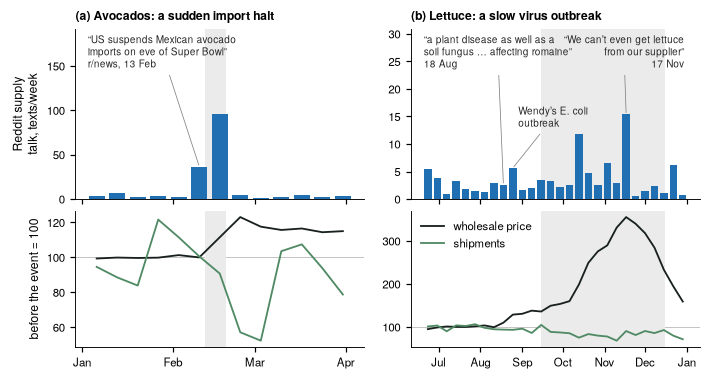

In [21]:
STORIES = [  # product, title, weeks shown, end of the baseline, events shaded, quotes (date, text, text position)
    dict(product="avocado", title="(a) Avocados: a sudden import halt", start="2022-01-03", end="2022-03-28",
         base_end="2022-02-07", events=["E12"],
         quotes=[("2022-02-13", "“US suspends Mexican avocado\nimports on eve of Super Bowl”\nr/news, 13 Feb",
                  ("2022-01-03", 0.97, "left"))]),
    dict(product="lettuce", title="(b) Lettuce: a slow virus outbreak", start="2022-06-20", end="2022-12-26",
         base_end="2022-08-15", events=["E15"],
         quotes=[("2022-08-18", "“a plant disease as well as a\nsoil fungus … affecting romaine”\n18 Aug",
                  ("2022-06-20", 0.97, "left")),
                 ("2022-08-23", "Wendy’s E. coli\noutbreak", ("2022-08-29", 0.55, "left")),
                 ("2022-11-17", "“We can’t even get lettuce\nfrom our supplier”\n17 Nov", ("2022-12-30", 0.97, "right"))]),
]

fig, axes = plt.subplots(2, 2, figsize=(6.5, 3.5), sharex="col", gridspec_kw={"height_ratios": [1.25, 1]})
mid = pd.Timedelta(days=3)   # draw each week at its middle
for c, st in enumerate(STORIES):
    prod, lo, hi = st["product"], pd.Timestamp(st["start"]), pd.Timestamp(st["end"])
    base_end = pd.Timestamp(st["base_end"])
    r = sig[(sig["product"] == prod) & sig["week_start"].between(lo, hi)].set_index("week_start")["n_supply"]
    p = nat[(nat["product"] == prod) & nat["week_start"].between(lo, hi)].set_index("week_start")["index"]
    q = ship[(ship["product"] == prod) & ship["week_start"].between(lo, hi)].set_index("week_start")["total_lb"]
    p, q = 100 * p / p[p.index < base_end].mean(), 100 * q / q[q.index < base_end].mean()
    at, ab = axes[0, c], axes[1, c]
    at.bar(r.index + mid, r, width=5.5, color=COLORS["supply"], lw=0)
    ab.plot(p.index + mid, p, color="#18211d", lw=1.2, label="wholesale price")
    ab.plot(q.index + mid, q, color="#4f8a64", lw=1.2, label="shipments")
    ab.axhline(100, color="0.7", lw=0.5, zorder=0)
    for e in events_ref[events_ref["event_id"].isin(st["events"])].itertuples():
        for ax in (at, ab):
            ax.axvspan(e.start_date, e.end_date + pd.Timedelta(days=1), color="0.92", lw=0, zorder=0)
    at.set_title(st["title"], loc="left", fontweight="bold")
    at.set_ylim(0, r.max() * 2.0)
    for d, text, (x, y, ha) in st["quotes"]:
        w = wk(d)
        at.annotate(text, xy=(w + mid, r.get(w, 0)), xytext=(pd.Timestamp(x), y * at.get_ylim()[1]), fontsize=6.5,
                    va="top", ha=ha, color="0.15",
                    arrowprops=dict(arrowstyle="-", color="0.5", lw=0.5, shrinkA=1, shrinkB=1))
    ab.xaxis.set_major_locator(mdates.MonthLocator())
    ab.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
axes[0, 0].set_ylabel("Reddit supply\ntalk, texts/week")
axes[1, 0].set_ylabel("before the event = 100")
axes[1, 1].legend(frameon=False, loc="upper left")
fig.tight_layout(h_pad=0.4, w_pad=1.5); fig.savefig(FIG / "two_supply_shocks.png", dpi=300); plt.show()

## 13. Weighting texts by upvotes or comments

So far every text counts once. Here each text's supply probability is multiplied by a weight from its upvotes
(`score`) or, for posts, its number of comments (`num_comments`; comments themselves get no comment count), and the
spike test of section 5 (z ≥ 3) is rerun on the weighted supply series. Three checks:
- **All weeks:** spikes near a documented event, against the base rate.
- **Time split:** pick the weighting on 2019–2022, then test it on 2023–2026, which played no part in the choice.
- **Google agreement:** share of Reddit supply spikes with a Google shortage/recall spike within one week (section 11).
  This check does not use the list of documented events.

In [22]:
WEIGHTS = {  # name -> weight per text (score = upvotes, num_comments = comments under a post)
    "equal (main signal)": lambda u, c: np.ones(len(u)),
    "upvotes: 1 + log(1 + upvotes)": lambda u, c: 1 + np.log1p(u),
    "upvotes: x2 if >= 10": lambda u, c: np.where(u >= 10, 2.0, 1.0),
    "upvotes: x3 if >= 10": lambda u, c: np.where(u >= 10, 3.0, 1.0),
    "upvotes: raw count": lambda u, c: u.astype(float),
    "comments: 1 + log(1 + comments)": lambda u, c: 1 + np.log1p(c),
    "comments: x2 if >= 10": lambda u, c: np.where(c >= 10, 2.0, 1.0),
    "comments: x3 if >= 10": lambda u, c: np.where(c >= 10, 3.0, 1.0),
    "both: 1 + log(1 + upvotes + comments)": lambda u, c: 1 + np.log1p(u + c),
}
up = obs["score"].clip(lower=0).fillna(0).to_numpy()
nc = obs["num_comments"].clip(lower=0).fillna(0).to_numpy()
grid = S.week_grid(START, END)
SPLIT = "2023-01-01"   # choose the weighting on 2019-2022, test it on 2023-2026

def weighted_supply_z(w):
    o = obs.assign(ws=obs["p_supply"] * w)
    parts = []
    for prod, g in o.groupby("product"):
        s = g.groupby("week_start")["ws"].sum().reindex(grid, fill_value=0.0)
        parts.append(pd.DataFrame({"product": prod, "week_start": grid,
                                   "z": S.trailing_z(np.log1p(s), 8, min_sd=0.2).to_numpy()}))
    return pd.concat(parts, ignore_index=True)

def enrichment(d):
    hit = d[d["z"] >= 3]
    k, n = int((hit["near_event"] != "").sum()), len(hit)
    p = binomtest(k, n, (d["near_event"] != "").mean(), alternative="greater").pvalue if n else np.nan
    found = sorted({e for v in hit["near_event"] if v for e in v.split(", ")})
    return n, k, round(p, 4), " ".join(found)

def google_agreement(d):
    d = d.merge(gw[["product", "week_start", "gz_shortage_or_recall"]], on=["product", "week_start"], how="left")
    rs = d[d["z"] >= 3]
    hits = 0
    for prod, w in zip(rs["product"], rs["week_start"]):
        m = d[(d["product"] == prod) & ((d["week_start"] - w).abs() <= pd.Timedelta(weeks=1))]
        hits += bool((m["gz_shortage_or_recall"] >= 3).any())
    return hits

rows, zs = [], {}
for name, f in WEIGHTS.items():
    d = weighted_supply_z(f(up, nc)).merge(sw[["product", "week_start", "near_event"]], on=["product", "week_start"])
    zs[name] = d
    n, k, p, found = enrichment(d)
    n1, k1, p1, f1 = enrichment(d[d["week_start"] < SPLIT])
    n2, k2, p2, f2 = enrichment(d[d["week_start"] >= SPLIT])
    g = google_agreement(d)
    rows.append({"weighting": name, "spikes": n, "near_event": k, "share": round(k / n, 2), "p": p, "events_found": found,
                 "spikes_2019_22": n1, "near_2019_22": k1, "share_2019_22": round(k1 / n1, 2) if n1 else np.nan,
                 "p_2019_22": p1, "spikes_2023_26": n2, "near_2023_26": k2,
                 "share_2023_26": round(k2 / n2, 2) if n2 else np.nan, "p_2023_26": p2, "events_found_2023_26": f2, "with_google_spike": g, "share_with_google": round(g / n, 2)})
wtab = pd.DataFrame(rows)
wtab.to_csv(TAB / "weighting_robustness.csv", index=False)
display(wtab)

best = wtab.iloc[1:].sort_values(["share_2019_22", "p_2019_22"], ascending=[False, True]).iloc[0]
eq = wtab.iloc[0]
print(f"Chosen on 2019-22: {best['weighting']} ({best['near_2019_22']}/{best['spikes_2019_22']} vs "
      f"{eq['near_2019_22']}/{eq['spikes_2019_22']} for equal weights). "
      f"Held-out 2023-26: {best['near_2023_26']}/{best['spikes_2023_26']} vs "
      f"{eq['near_2023_26']}/{eq['spikes_2023_26']}.")

# which spike weeks the chosen weighting removes or adds, with the most supply-like text of the week
a, b = zs[eq["weighting"]], zs[best["weighting"]]
A = set(map(tuple, a.loc[a["z"] >= 3, ["product", "week_start"]].to_numpy()))
B = set(map(tuple, b.loc[b["z"] >= 3, ["product", "week_start"]].to_numpy()))
diff = []
for change, keys in [("removed", A - B), ("added", B - A)]:
    for prod, w in sorted(keys):
        wk_ = obs[(obs["product"] == prod) & (obs["week_start"] == w)]
        top = wk_.sort_values("p_supply", ascending=False).iloc[0]
        diff.append({"change": change, "product": prod, "week_start": pd.Timestamp(w).date(),
                     "near_event": sw.loc[(sw["product"] == prod) & (sw["week_start"] == w), "near_event"].iloc[0],
                     "supply_texts": round(wk_["p_supply"].sum(), 1), "top_subreddit": top["subreddit"],
                     "top_text": re.sub(r"\s+", " ", str(top["text"]))[:120]})
display(pd.DataFrame(diff))

,weighting,spikes,near_event,share,p,events_found,spikes_2019_22,near_2019_22,share_2019_22,p_2019_22,spikes_2023_26,near_2023_26,share_2023_26,p_2023_26,events_found_2023_26,with_google_spike,share_with_google
0,equal (main signal),55,23,0.42,0.0003,E1 E11 E12 E14 E15 E17 E18 E19 E20 E22 E23 E24 E26 E29 E32 E5 E6 E7 E8 E9,26,12,0.46,0.0035,29,11,0.38,0.0257,E17 E18 E19 E20 E22 E23 E24 E26 E29 E32,16,0.29
1,upvotes: 1 + log(1 + upvotes),39,16,0.41,0.0034,E1 E11 E12 E18 E19 E20 E22 E23 E24 E26 E29 E32 E5 E6 E7 E9,16,7,0.44,0.0335,23,9,0.39,0.0343,E18 E19 E20 E22 E23 E24 E26 E29 E32,13,0.33
2,upvotes: x2 if >= 10,50,20,0.40,0.0016,E1 E11 E12 E14 E15 E17 E18 E19 E20 E22 E23 E24 E26 E29 E31 E32 E5 E6 E7 E9,22,9,0.41,0.0265,28,11,0.39,0.0195,E17 E18 E19 E20 E22 E23 E24 E26 E29 E31 E32,16,0.32
3,upvotes: x3 if >= 10,49,18,0.37,0.0077,E1 E11 E12 E14 E15 E17 E18 E19 E20 E22 E23 E24 E26 E29 E31 E32 E6 E7 E9,23,7,0.30,0.1893,26,11,0.42,0.0106,E17 E18 E19 E20 E22 E23 E24 E26 E29 E31 E32,14,0.29
4,upvotes: raw count,50,18,0.36,0.0097,E1 E10 E11 E12 E19 E20 E22 E24 E29 E32 E33 E5 E6 E7 E8 E9,28,10,0.36,0.0513,22,8,0.36,0.0680,E19 E20 E22 E24 E29 E32 E33,17,0.34
5,comments: 1 + log(1 + comments),41,16,0.39,0.0060,E1 E11 E12 E18 E19 E20 E22 E23 E24 E31 E32 E4 E5 E7 E9,17,7,0.41,0.0469,24,9,0.38,0.0450,E18 E19 E20 E22 E23 E24 E31 E32,16,0.39
6,comments: x2 if >= 10,52,20,0.38,0.0028,E1 E11 E12 E14 E15 E18 E19 E20 E22 E23 E24 E26 E29 E31 E32 E5 E6 E7 E9,23,9,0.39,0.0357,29,11,0.38,0.0257,E18 E19 E20 E22 E23 E24 E26 E29 E31 E32,16,0.31
7,comments: x3 if >= 10,51,19,0.37,0.0053,E1 E11 E12 E18 E19 E20 E22 E23 E24 E26 E29 E31 E32 E5 E6 E7 E9,24,8,0.33,0.1099,27,11,0.41,0.0145,E18 E19 E20 E22 E23 E24 E26 E29 E31 E32,18,0.35
8,both: 1 + log(1 + upvotes + comments),42,18,0.43,0.0010,E1 E11 E12 E18 E19 E20 E22 E23 E24 E26 E29 E31 E32 E4 E5 E6 E7 E9,16,8,0.50,0.0093,26,10,0.38,0.0297,E18 E19 E20 E22 E23 E24 E26 E29 E31 E32,14,0.33


Chosen on 2019-22: both: 1 + log(1 + upvotes + comments) (8/16 vs 12/26 for equal weights). Held-out 2023-26: 10/26 vs 11/29.


,change,product,week_start,near_event,supply_texts,top_subreddit,top_text
0,removed,avocado,2019-02-11,,6.4,Costco,I was just going to ask about the avocados yesterday. I just got a bad batch from Mexico at Costco on Feb ...
1,removed,avocado,2019-05-27,,12.8,KitchenConfidential,People been shot in California over avocado theft. Shit is no joke. They’re only ripe once a year and a fa...
2,removed,avocado,2020-06-22,,11.6,Chipotle,We just swapped from Mexican Hass over to Peruvian Avocados for the summer because the Mexican avocados ar...
3,removed,avocado,2022-02-14,E12,95.8,news,Too bad most of the shitty Mexican avocados I get lately just skip ripening entirely and rot.
4,removed,avocado,2023-08-14,,58.1,Chipotle,Chipotle (and every other big corporate company) will always crack down on stores that do this while also ...
5,removed,avocado,2024-07-01,E20,84.2,Costco,"Unless the Avocados are from Mexico or California, you will find a significant amount of loss due to handl..."
6,removed,cucumber,2020-07-13,,7.2,vegetablegardening,I'm having the devil of a time this year too. I dumped a bunch of finished homemade compost on the spot I ...
7,removed,cucumber,2021-07-19,,7.6,Cooking,"yes definitely, from my understanding it's because of climate change as cucumbers get more bitter in hot w..."
8,removed,cucumber,2023-05-15,,4.2,vegetablegardening,"Here’s to successful harvest - may you have more than just one cucumber! 😁 Remember, every gardener learns..."
9,removed,cucumber,2026-07-13,,19.8,Cooking,"Buy local, direct from growers when you can. We are buying locally grown red lettuce and spinach, cucumber..."
